# Intended Learning Outcomes


In this tutorial you will design, estimate and test a text classifier. As you've learnt about classification before in ML1, the tutorial is focused on the particularities that arise from having text as input, rather than on the internals of classification algorithms. 

The tutorial has three parts to it, their intended learning outcomes (ILOs) are shown below:


* _Digital Text_: the student ...
    * understands how text is represented in a computer program;
    * understands and is able to explain the need for strategies for text segmentation;
    * understands and is able to explain the challenges posed by text segmentation;
    * understands and is able to verify challenging problems intrinsic to language (such as Heap's law);
    * understands and is able to explain an unsupervised algorithm of text segmentation based on compression techniques;
* _Text Classification_: the student ... 
    * understands and is able to explain a modular approach to text classification composed of a probabilistic model and a decision rule;
    * understands and is able to explain the need for vector-valued representations of text;
    * is able to design hand-crafted representation spaces;
    * understands and is able to explain softmax regression;
* _Experiment_: the student ...
    * is able to implement and evaluate text classifiers based on variants of softmax regression using standard libraries;
    * is able to improve a model via changes to its representation space and the architecture of the regressor;
    * is able to compare and judge different design changes with the support of statistical inference.

## Suggested study plan

* Week 1: tutorial

| When | Werkcollege 1 | Werkcollege 2 |
| --- | --- | --- |
| Before |  [Setup](setup) your Jypyter Lab instance. Familiarise yourself with the section [Digital Text](digital-text) (incl. all of its subsections). Your goal is to get a sense of what the sections cover and the kind of knowledge they contain and/or depend on. If you find that some of them go into topics that you need to refresh, consider refreshing those before the live session too. | Familiarise yourself with the rest of the notebook (that is, the sections [Text Classification](text-classification) and [Experiment](experiment), incl. all of their subsections). Your goal is to get a sense of what the sections cover and the kind of knowledge they contain and/or depend on. If you find that some of them go into topics that you need to refresh, consider refreshing those before the live session too.  |
| First half | Work from the top until [Heap's Law](#heaps-law) and focus on the suggested exercise in that section. |  Work through [Text Classification](text-classification) and its subsections.|
| Second half | Work through the rest until [Byte-Pair Encoding](#byte-pair-encoding) and focus on the suggested exercise in that section. | Work through [Experiment](experiment) and its subsections. |
| After |  Reflect on the various _Questions_ sections under [Digital Text](digital-text) and its subsections. | Reflect on the various _Questions_ and _Exercises_ sections under [Text Classification](text-classification) and [Experiment](experiment). |

* Week 2: project
* Week 3: oral assessment

## Assessment

The practical (tutorial + mini project) is assessed orally, in the week _after_ the practical's conclusion. Make sure to seek the detailed schedule with your TA. 
The assessment is composed of some questions on the topics of the tutorial notebook and some questions on your mini project. The sections with _Questions_ or _Exercise_ in their header contain examples of the questions we may ask (both in form and level) about the tutorial part. Exercises marked as _suggested_ could be skipped in a first pass through the tutorial, but we may still ask questions about them. Instructions for the mini project can be found in the project notebook.

## Resources

* We often refer to [Chapter 2 of SLP3](https://web.stanford.edu/~jurafsky/slp3/2.pdf)
* Slides used in class: [check course website](https://nlp-illc.github.io/nlp1/).
* [A refresher on probability theory](https://raw.githubusercontent.com/wilkeraziz/wilkeraziz.github.io/master/assets/pdfs/lecture-notes-appendix-B.pdf)

Other resources that you are less likely to need, but which we refer to:
* [Koller's Probabilistic Graphical Models](https://mitpress.mit.edu/9780262013192/probabilistic-graphical-models/)
* [Bishop's Pattern Recognition and Machine Learning](https://www.microsoft.com/en-us/research/wp-content/uploads/2006/01/Bishop-Pattern-Recognition-and-Machine-Learning-2006.pdf)

## Setup 

We are using `python3.14` and the packages listed in `requirements.txt` at the root of the repository. The README.md file contains further instructions. 

In [1]:
%load_ext autoreload
%autoreload 2    

In [2]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning) 

In [3]:
# some helper functions and classes (no need to check them now)
import sys
from pathlib import Path

# Assuming the working directory is root/part1 or root/part2
root = Path.cwd().parent
sys.path.insert(0, str(root))

from part1 import utils, clslib, bpe, loglin, smlp, analysis

In [4]:
# save models and outputs there to keep the directory tree organised
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 
results_folder

PosixPath('results')

# Digital Text

In Python digital text is represented in memory using Unicode, an abstract scheme to represent a very large set of possible symbols (or characters), large enough to include the symbols necessary to render the scripts of all languages known to us and yet leave space for emojis and more. 

Code points (the unit of unicode) vary from 1 to 4 bytes in length. In a computer file system though, digital text is stored in a more compact manner, by reference to a specific _encoding_ (think of it as a way to interpret code points, or a subset of code points). [Section 2.3 of SLP3](https://web.stanford.edu/~jurafsky/slp3/2.pdf) is an excellent overview of unicode and encoding, here we cover the minimum you need for basic operations.

Just to give you an idea that this matters, here you have some examples:

In [5]:
!file --mime-encoding digital-text-example.*  # if you git cloned this repo, then this will list 3 files and their encodings

digital-text-example.ascii:      us-ascii
digital-text-example.iso-8859-1: iso-8859-1
digital-text-example.utf-8:      utf-8


We can read these files as follows:

In [6]:
for encoding in ['ascii', 'iso-8859-1', 'utf-8']:  
    print(f"Encoding: {encoding}")
    with open(f'digital-text-example.{encoding}', 'r', encoding=encoding) as fi:
        text = fi.readline().strip()
        print(f" Text: {text}\n")       

print("When you are wrong about a file's encoding, you may get an exception:")
try:    
    with open(f'digital-text-example.iso-8859-1', 'r', encoding='utf-8') as fi:
        text = fi.readline().strip()
        print(f" Text: {text}")    
except UnicodeDecodeError as e:        
    print(f"{e}\n")

print("Other times, when you are wrong about a file's encoding, you won't get an error, but the text will be corrupted")
try:    
    with open(f'digital-text-example.utf-8', 'r', encoding='iso-8859-1') as fi:
        text = fi.readline().strip()
        print(f" Text: {text}")    
except UnicodeDecodeError as e:
    print(e)

Encoding: ascii
 Text: Lorem ipsum dolor sit amet, consectetur adipiscing elit.

Encoding: iso-8859-1
 Text: Café naïf: élève déjà vu, façade en rénovation.

Encoding: utf-8
 Text: Café ☕ — naïve résumé; 北; 😀

When you are wrong about a file's encoding, you may get an exception:
'utf-8' codec can't decode byte 0xe9 in position 3: invalid continuation byte

Other times, when you are wrong about a file's encoding, you won't get an error, but the text will be corrupted
 Text: CafÃ© â â naÃ¯ve rÃ©sumÃ©; å; ð


So long as you know the file's encoding and you read/write coherently with it, once your text is in Python, you can count on it being represented as a sequence of Unicode code points. You can view it right away on a Jupyter notebook like this one, and you can do various operations on it (concatenate, search, match regular expressions, determine length in characters, etc.) and expect these operations to work reasonably (as opposed to yield strange results due to misinterpretation of byte sequence into incorrect character sequences). 

## Text Segmentation

If you worked through the examples so far, you realised that working with text as if it were indivisible is quite constraining. You must also have realised that digital text is in fact a *sequence* of code points (which in turn are sequences of bytes).

But these realisations raise a question: what sort of unit are we going to consider as the right one when regarding text as a sequence of parts? 

Given your command of English, you might have answered the question above quite simply as follows: **words**.
Well, it turns out there's nothing _simple_ about it.

How many words do you recognise in the following sample of English text?

In [7]:
example1 = "They picnicked by the pool, then lay back on the grass and looked at the stars."

Clearly, it depends on how we count:

In [8]:
import re

example1_tokenization1 = example1.split() # tokenize on space
example1_tokenization2 = re.sub(r'([^\w\s]|_)',r' \1 ',example1).split() # separate punctuation, then tokenize on space
example1_tokenization3 = re.sub(r'([^\w\s]|_)',r'',example1).split() # discard punctuation, then tokenize on space

print(len(example1_tokenization1), example1_tokenization1)
print(len(example1_tokenization2), example1_tokenization2)
print(len(example1_tokenization3), example1_tokenization3) # note that this is as long as the first, but the token sequences differ
print("Do 1st and 3rd have same length?", len(example1_tokenization1) == len(example1_tokenization3), "\nAre 1st and 3rd equal?", example1_tokenization1 == example1_tokenization3)

16 ['They', 'picnicked', 'by', 'the', 'pool,', 'then', 'lay', 'back', 'on', 'the', 'grass', 'and', 'looked', 'at', 'the', 'stars.']
18 ['They', 'picnicked', 'by', 'the', 'pool', ',', 'then', 'lay', 'back', 'on', 'the', 'grass', 'and', 'looked', 'at', 'the', 'stars', '.']
16 ['They', 'picnicked', 'by', 'the', 'pool', 'then', 'lay', 'back', 'on', 'the', 'grass', 'and', 'looked', 'at', 'the', 'stars']
Do 1st and 3rd have same length? True 
Are 1st and 3rd equal? False


It also depends on what language we are interested in

In [9]:
example2 = "姚明进入总决赛"  # "Yao Ming reaches the finals"

The Chinese language, as every natural language (including sign languages), works with instances of what a linguist calls a word, but _written_ Chinese does not rely on the concept of an **orthographic word**, namely, a meaningful sequence of symbols bounded by spaces or punctuation marks. In written Chinese, the characters themselves tend to each represent a unit of meaning. 

So perhaps we should work at the character level then?

In [10]:
example2_tokenization1 = [c for c in example2]
example2_tokenization1

['姚', '明', '进', '入', '总', '决', '赛']

Not quite, this 'tendency' is not as regular as you might expect. 

It can be argued that `example2` above is better interpreted as 3 or even 5 words. See the segmentations and their gists below:

In [11]:
example2_tokenization2 = ['姚明', '进入', '总决赛'] # gist: "YaoMing reaches finals"
example2_tokenization3 = ['姚', '明', '进入', '总', '决赛'] # gist: "Yao Ming reaches overall finals"
print(len(example2_tokenization1), example2_tokenization1)
print(len(example2_tokenization2), example2_tokenization2)
print(len(example2_tokenization3), example2_tokenization3)

7 ['姚', '明', '进', '入', '总', '决', '赛']
3 ['姚明', '进入', '总决赛']
5 ['姚', '明', '进入', '总', '决赛']


Even when you can count on word boundaries to be there (like in English), it's still not easy to spot them systematically due to many reasons including complex morphology (more on that soon), ambiguity, punctuation and other phenomena (e.g., fillers when working with spoken language or sign languages).

The examples above are from SLP3, and we encourage you to read [sections 2.0, 2.1 and 2.2](https://web.stanford.edu/~jurafsky/slp3/2.pdf).

### Questions

1. Suppose you are working with European languages. Do you see any shortcomings of treating text as a sequence of characters (that is, not defining a larger unit such as what you typically regard as an orthographic word in English)?
2. Continuing from (1). Suppose you define a way to detect word boundaries for English. Do you expect it to work reasonably well for other European languages? Do motivate your answer.
3. Suppose you now have a way to detect word boundaries for all European languages, perhaps this is one set of rules that works for all languages or a collection of sets of rules, each set being language specific; never mind the strategy, just assume you have access to it. Now, do you expect the _vocabulary_ of _known_ (or at least _observed_) words to be roughly of similar size across languages?

## Heap's Law

Do you know [Heap's law](https://en.wikipedia.org/wiki/Heaps%27s_law)? As you can see from its Wikipedia page, it's a mathematical formulation of the following empirical phenomenon:
1. As we observe more text, the number of distinct words we encounter keeps growing;
2. The relationship between number of tokens $n$ and number to distinct tokens $V(n)$ (also called types) is linear when plotted in logarithmic axes. Mathematically, $\log V(n) = \log K + \beta \log n$, or, in power-law form, $V(n) = Kn^\beta$. The parameters $K$ and $\beta$ are language- and even dataset-specific.


**Suggested exercise**

How about you verify Heap's law? You will need a _corpus_ (fancy word for 'collection of texts') and a way to discern orthographic words, let's call the latter a _tokenization procedure_ (or a _tokenizer_), more on that below. You can then plot the relevant observations ($n$ and $V(n)$) and inspect if the law seems to hold, you can even try to estimate the parameters of the law.

A **tokenizer** gets a string of characters and converts it to a sequence of symbols, called tokens; the python function `split()` available for strings is a crude tokenizer that chops the string at blank characters (such as space). The resulting symbols are in effect what we treat as units, and, for all practical purposes, the tokenizer itself operationalises our definition of what counts for orthographic words. 

For tokenization, you could use simple rules that are reasonable for the language you want to analyse, or you can load a tokenizer that's known to produce reasonable results such as those in the [NLTK tokenize](https://www.nltk.org/api/nltk.tokenize.html) package (see for example, punkt). Feel free to use any one such strategy and even try comparing a couple. Just keep an eye on how much time you dedicate to this, so you still have time for the rest of the fun ahead.

Warning: in case you already know about BPE tokenization (covered later in this tutorial), to reproduce Heap's law it's better if you use a tokenizer that is more linguistically-informed than BPE (such as those in NLTK).

<details>
    <summary> If you could use a hint, here's a sketch of what you need (but do try a bit without the hint).
    </summary></br>


If you have a corpus and a tokenizer in place, then you just need to iterate over the token positions in the corpus and plot at each such position the total number of token occurrences seen up until that point vs. the number of _distinct_ tokens (or 'types') seen up until then. If you use a log-log plot, this will give you something close to a straight line. If you want to test the fit of a straight line to the data, you can use scipy or scikit-learn to find the coefficients (offset and slope) of a linear fit, and a measure of discrepancy between the fitted line and the observed points. 


---

</details>
</details></br>

For English, you could use the AG news dataset, which we will be working with later on in the _Experiments_ section. 

In [12]:
texts = utils.download_ag_news_texts()
print(f"Downloaded {len(texts)} texts; the first of which is shown below:\n{texts[0]}")

Downloaded 120000 texts; the first of which is shown below:
Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.


Or any other dataset you like (the course website has a list of recommendations).

In [13]:
# YOUR CODE HERE

If you want to go the extra mile, in your self-study time, you could look into Zipf's law which captures something rather interesting about the distribution of the _frequencies_ of words in text. For example, you might want to check [this tutorial from another course](https://github.com/probabll/ntmi-tutorials/blob/main/Rank%20frequency.ipynb).

## Words

Our everyday use of the word _word_ isn't sufficiently precise. So let's briefly discuss some technicalities.

To a linguist, a **word** is a linguistic object built out of meaningful parts by a mental system or module of "word formation". Even if built out of parts, a word, in this technical sense, behaves as indivisible with respect to the mental system or module of "sentence formation" which composes words into phrases and sentences. The system of word formation is called _morphology_ and the parts which it manipulates and composes to form words are called **morphemes**. The system of sentence formation is called _syntax_. For a little more on morphology, see [section 2.2 of SLP3](https://web.stanford.edu/~jurafsky/slp3/2.pdf).   

For example:
* _cat_ is a word composed of the morpheme `cat` ([a kind of mammal](https://en.wikipedia.org/wiki/Cat));
* and _cats_ is a word composed of the morphemes `cat` and `-s` (a plural suffix);
* the _cat_ within _catastrophic_ is unrelated to the morpheme `cat`, rather, _catastrophic_ is a word composed of `cata-` (a prefix meaning 'down', 'against' or 'thoroughly'), `strophe` (a root meaning 'to turn') and `-ic` (a suffix meaning 'having the character or form of' or 'pertaining to').

Linguistic stuff like morphemes (e.g., `cat`, `-s`, `cata-`, `strophe` and `-ic`) are stored in the mental dictionary along with their meanings by rote memorisation (i.e., a wholy conventional association between a symbol and its meaning or function), whereas linguistic stuff like words (.e.g, _cat_, _cats_ and _catastrophic_) are the product of morphology.

<details>
    <summary> A short digression on listemes.
    </summary></br>

When something has to be rote-memorised, that is, its meaning cannot be predicted by analysis of its parts, a (psycho)linguist may also call it a **listeme**. Listemes differ from morphemes in that listemes may have what seems to be an internal structure, with parts to it, but careful analysis shows that the meaning of the whole is still conventional, hence cannot be inferred from the parts. For example, the listeme _kick the bucket_ is not about kicking nor about buckets, it's a form of dying or of stopping to function and this cannot be derived from the morphemes `kick`, `the` and `bucket`, rather, the child (or the adult) must memorise and store it in their mental dictionary. 


---

</details>
</details></br>


The examples above motivate us to treat _morphemes_ as units of text segmentation, for they are:
1. meaningful: they index something we know;
2. conventional: we cannot deduce their meaning, rather we memorise them, but, importantly, we and others in our linguistic community use them in the same way;
3. productive: they interact to form longer, meaningful linguistic objects in predictable ways.

But, there is a _but_.

Written language is a tool crafted to yield a persistent, visual or tactile representation of a natural (spoken or sign) language using a structured system of symbols (a _script_). But no written language bothers to mark the boundaries of morphemes (nor should they; except for linguists, language users' awareness of the logic of morphology is  unconscious). While many written languages employ special symbols such as spaces or dots to mark the boundaries between words, many don't (see [_scriptio continua_](https://en.wikipedia.org/wiki/Scriptio_continua)). Those that do, at best mark the finished products of morphology, not their meaningful component parts. But the finished products of morphology can be very complex due to its combinatorial nature (e.g., in English a verb comes in one of 4 forms, in Portuguese that number goes up to about 50, in Turkish it is about two million). 

The essence of the problem of text segmentation then has two parts. First, the concept of an orthographic word is not intrinsic to natural languages. What _is_ intrinsic to natural langages (spoken languages and sign languages) are words in the linguist's technical sense (ie, listemes and the products of morphology). Second, even when linguistic words are easy to identify, identifying their meaningful parts pose a difficult engineering challenge to NLP systems, which are not equipped with our species' ways of knowing.

The difficulty that linguists and psycho-linguistics face in completely describing the logic underlying word formation may come across as a tall wall for NLP research and, for a while, it may have been seen that way indeed. But, as we will see next, we found an engineering solution that is useful enough. 

## Byte-Pair Encoding

In a modern fashion, we will address the problem of text segmentation with a data-driven approach, and formulate a strategy that can be expected to work reasonably well across most languages of interest, so long as we have enough data to inform our strategy's choices.

This time, instead of trying to characterise rules that recognise linguistic words, we seek to 'learn' a vocabulary of units that is no bigger than what we are willing to handle while being comprehensive enough that we can compose _any_ string in the language (or language*s*). We will refer to these units as _subword units_. These subword units are unlike morphemes in that we do not require them to be meaningful nor conventional, we only require them to be productive (in the sense of reusable).

_Byte-pair encoding_ (or BPE for short) is one of the broadly employed algorithms for this form of text segmentation. 

Building a BPE tokenizer (as they are also called) involves learning the BPE vocabulary of subword units (or _BPE tokens_). Then, once the tokenizer is built, we can tokenize unicode strings into sequences of BPE tokens as well as merge BPE token sequences back into their original unicode strings.

**Fitting the BPE vocabulary to data.** The basic idea is to start the vocabulary of BPE units with the characters in the script(s) of the language(s) we are interested in and expand this vocabulary with longer units until we reach a maximum vocabulary size. Longer units are obtained by merging existing units; of the possible merges, we realise first those that are most productive, in the sense that they occur the most in some training data. 

**Tokenizing new text.** After training, we present the tokenizer with text (a unicode string) and the tokenizer treats the string as a sequence of characters and then iteratively performs the possible merges, but reproducing the order these merged units were formed during training (this order is recorded when we fit the BPE vocabulary to data).

For a detailed presentation of the relevant algorithms, see [Section 2.4](https://web.stanford.edu/~jurafsky/slp3/2.pdf) of the textbook or the original paper [(Sennrich et al, 2016)](https://aclanthology.org/P16-1162/).

### Pretokenization

BPE starts from a _pretokenizer_ used to treat a corpus (i.e., a list of strings) as a long sequence of tokens. These are not yet our BPE tokens. For whatever strange reason you will often find implementations (and explanations in the literature) that refer to these as _words_ (perhaps because with English text, these will many times be indeed orthographic words, but don't let this choice of terminology slow you down). 

This pretokenizer could be indeed as simple as `[c for c in text]` in Python, but here we will use a variant of `text.split()`.
Our variant will mark the boundry of a (pretokenizer) token with a simple that looks like `_` (we use a Unicode char that's not, in fact, `_`, but it looks like it; the idea is to use something very unlikely to occur in real text). 

We demonstrate it below with a (not very interesting, but at least rather short) demo corpus:

In [14]:
bpe_demo_corpus = [
    "low lower newest widest",
    "low lowest newer wider",
]
bpe_demo_prepared_corpus = bpe.prepare_corpus(bpe_demo_corpus)
bpe_demo_prepared_corpus

['low', '▁lower', '▁newest', '▁widest', 'low', '▁lowest', '▁newer', '▁wider']

### Initial BPE Vocabulary

Let's start by determining the vocabulary of characters of our BPE tokenizer. This could be all characters in Unicode, or some subset of Unicode; here we will use all distinct characters in the corpus. 

In [15]:
bpe_demo_char_vocab = set(
    ch
    for token in bpe_demo_prepared_corpus
    for ch in token
)
bpe_demo_char_vocab

{'d', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w', '▁'}

And now we are ready to initialise our BPE vocabulary (the collections of BPE tokens discovered so far). We start with the characters that we've seen and a placeholder character which we will use whenever we find an unseen character in the future.

In [16]:
bpe_demo_vocab = set(bpe_demo_char_vocab)
# here we add an "UNK" character: '⁇'
bpe_demo_vocab.add(u"\u2047") # if in the future we bump into a character never seen before, we will replace it by this one
bpe_demo_vocab

{'d', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w', '⁇', '▁'}

### Count pretokenized tokens

Next, we now count the unique (pretokenizer) tokens in the prepared corpus. This will helps us determine which BPE tokens to merge.

You will see that we treat a pretokenized token as a sequence of _characters_. That's because at this point our BPE vocabulary is made entirely of single characters. As the algorithm progresses, we will be repeating this step and you will see that once larger units are formed, those larger units will be visible within our representation of the pretokenized counter.

In [17]:
from collections import Counter
bpe_demo_word_counts = Counter(tuple(word) for word in bpe_demo_prepared_corpus)
bpe_demo_word_counts

Counter({('l', 'o', 'w'): 2,
         ('▁', 'l', 'o', 'w', 'e', 'r'): 1,
         ('▁', 'n', 'e', 'w', 'e', 's', 't'): 1,
         ('▁', 'w', 'i', 'd', 'e', 's', 't'): 1,
         ('▁', 'l', 'o', 'w', 'e', 's', 't'): 1,
         ('▁', 'n', 'e', 'w', 'e', 'r'): 1,
         ('▁', 'w', 'i', 'd', 'e', 'r'): 1})

### Count pairs

We can now go from the counts of pretokenized tokens to the occurrences of _pairs_ of BPE tokens.

In [18]:
bpe_demo_pair_counts = Counter()
for symbols, frequency in bpe_demo_word_counts.items():
    for left, right in zip(symbols, symbols[1:]):
        bpe_demo_pair_counts[(left, right)] += frequency
bpe_demo_pair_counts

Counter({('l', 'o'): 4,
         ('o', 'w'): 4,
         ('w', 'e'): 4,
         ('e', 'r'): 3,
         ('e', 's'): 3,
         ('s', 't'): 3,
         ('▁', 'l'): 2,
         ('▁', 'n'): 2,
         ('n', 'e'): 2,
         ('e', 'w'): 2,
         ('▁', 'w'): 2,
         ('w', 'i'): 2,
         ('i', 'd'): 2,
         ('d', 'e'): 2})

In [19]:
bpe_demo_best_pair = min(
    bpe_demo_pair_counts,
    key=lambda pair: (-bpe_demo_pair_counts[pair], pair)  # if the count is the same, we use lexicographic order (just to have some criterion to break ties)
)
bpe_demo_best_pair

('l', 'o')

At this point we know the most frequent pair, and _that_ is the first pair we will be merging. We keep a record of the order of merge operations, as this information (that is, the order) will be used when segmenting new text.

In [20]:
from collections import OrderedDict
bpe_demo_merges = OrderedDict()

bpe_demo_merges[bpe_demo_best_pair] = bpe_demo_pair_counts[bpe_demo_best_pair]  # we really only need the order (which the OrderedDict ensures), but we in this version we are also keeping the count
bpe_demo_merges

OrderedDict([(('l', 'o'), 4)])

A merge consists in: 1) adding the merged pair to the BPE vocabulary

In [21]:
bpe_demo_vocab.add(bpe_demo_best_pair[0] + bpe_demo_best_pair[1])
bpe_demo_vocab  # see 'lo' is now in the set

{'d', 'e', 'i', 'l', 'lo', 'n', 'o', 'r', 's', 't', 'w', '⁇', '▁'}

and 2) merging the occurrences of the pair also in our corpus. The helper function `bpe.merge_pair_in_corpus` helps with that:

In [22]:
bpe_demo_word_counts = bpe.merge_pair_in_corpus(bpe_demo_word_counts, bpe_demo_best_pair)
bpe_demo_word_counts # see how occurrences of 'l', 'o' are now 'lo'

Counter({('lo', 'w'): 2,
         ('▁', 'lo', 'w', 'e', 'r'): 1,
         ('▁', 'n', 'e', 'w', 'e', 's', 't'): 1,
         ('▁', 'w', 'i', 'd', 'e', 's', 't'): 1,
         ('▁', 'lo', 'w', 'e', 's', 't'): 1,
         ('▁', 'n', 'e', 'w', 'e', 'r'): 1,
         ('▁', 'w', 'i', 'd', 'e', 'r'): 1})

**Suggested exercise**

If you iterate over the operations in this subsection (that is, _count pairs_, _determine most frequent pair_, _merge the most frequent pair_ adding it to the vocabulary and modifying the word counts) until a BPE vocabulary size is reached, or a maximum number of merges is performed, or no pair exceeds a minimum frequency, or there's nothing else to merge, you will have fitted a BPE vocabulary to the demo corpus. You might want to try to do it yourself (in any case, we have packaged an implementation in `bpe.fit_bpe`). 

In [23]:
# Your code here

We packaged the complete loop for you in `bpe` (in particular, in `fit_bpe`). See below.

In [24]:
bpe_demo_model = bpe.fit_bpe(bpe_demo_prepared_corpus, 10)
bpe_demo_model

{'merges': [('l', 'o'),
  ('lo', 'w'),
  ('e', 'r'),
  ('e', 's'),
  ('es', 't'),
  ('e', 'w'),
  ('i', 'd'),
  ('n', 'ew'),
  ('w', 'id'),
  ('▁', 'low')],
 'vocabulary': {'d',
  'e',
  'er',
  'es',
  'est',
  'ew',
  'i',
  'id',
  'l',
  'lo',
  'low',
  'n',
  'new',
  'o',
  'r',
  's',
  't',
  'w',
  'wid',
  '⁇',
  '▁',
  '▁low'},
 'character_vocab': {'d', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w', '▁'},
 'UNK': '⁇'}

**Suggested exercise**

Segmenting new text amounts to pretokenizing the input string and then performing all possible merges amongst those that we have recorded, in the specific order that we performed them in training. You might want to try and do it yourself (again, `bpe.segment_text` packages the necessary code in case you just want a solution). 

In [25]:
# Your code here

See some examples below, which also show the use of the UNK character.

In [26]:
for new_text in ["lowest newer!", "newer lowest!", "newer löwell"]:
    print(new_text, "-->", bpe.segment_text(new_text, bpe_demo_model))

lowest newer! --> ['low', 'est', '▁', 'new', 'er', '⁇']
newer lowest! --> ['new', 'er', '▁low', 'est', '⁇']
newer löwell --> ['new', 'er', '▁', 'l', '⁇', 'w', 'e', 'l', 'l']


In the _Experiment_ section of this tutorial, we demonstrate how to _use_ a standard BPE implementation from the Python package Hugging Face `tokenizers`.

### Questions

By segmenting texts with a BPE tokenizer, we are able to view text as a divisible object, specifically, a _sequence_ of data-driven units called BPE tokens (as opposed to say merely a sequence of characters). 

Now that you have some experience using a BPE tokenizer, let's reflect a bit. 

1. What effect do you expect the hyperparameters of the algorithm (i.e. the maximum vocubulary size, maximum number of merges and minimum frequency to conduct a merge) to have on the final collection of BPE tokens? Do you expect tokens to change in some predictable way?
2. How may this, in turn, affect the tokens' 'informativeness' for NLP applications (for example, an orthographic word carries information that a speaker of the language can retrieve, while an isolated character carries much less)?
3. How can other design decisions, such as lowercasing, sophisticated pre-tokenization, etc, which could be deployed before BPE training, can affect that as well?

# Text Classification

So far we focused on how to regard digital text as a sequence of parts, this will help us with our ultimate goal for the week, namely, to develop a _text classifier_. This section is a short technical overview of text classification.  

In NLP, the text classification task typically involves taking digital **text** as input and outputing a **class** out of $K$ possible 'named classes' (e.g., in sentiment classification we might work with the possibilities `negative`, `neutral` and `positive`):

```mermaid
flowchart LR

A["input text ($$x$$)"] --> B(text classifier) --> C1["output class ($$y$$)"]
```

We call this a $K$-way text classifier (because it works with a label space with $K$ possible values of the target/output variable).


Let's introduce some conventions: 

* $x$ is used to denote some input text;
* $\mathcal X$ then is used to denote the set of all possible texts (this is usually an unbounded set, with countably infinitely many elements in it), hence we can say that a given $x$ is a member of $\mathcal X$ or $x\in \mathcal X$ for short;
* $y$ is used to denote an output class, a member of an outcome space $\mathcal Y$, very often (and definitely in this tutorial) the outcome space is finite and has size $K=|\mathcal Y|$;
* the outcome space $\mathcal Y$ is a set of 'named categories', it is often convenient to represent these names as a collection $\{c_1, \ldots, c_K\}$, with each name associated with an integer from $1$ to $K$, this is convenient for we can use $c_k \in \mathcal Y$ and $k \in [K]$ interchangeably (as it is rather clear that when we use $k$ (a number) we really mean the $k$th category $c_k$ (a symbol);
* we have a helper class, `clslib.NamedClasses`, that you can use to manage a fixed correspondence between symbols (e.g.,  named categories) and integers in code (see how to use it below).

In [27]:
example_outcome_space = clslib.NamedClasses(['negative', 'neutral', 'positive'])
print(example_outcome_space)  # python lists are 0-based, hence the integers associated with the named categories go from 0 to K-1

0: negative, 1: neutral, 2: positive


A minimum interface for a text classifier then looks as follows:

In [28]:
class TextClassifier:
    """
    A text classifier is able to map text (str) to a class (str), 
    we do so via the special method __call__.
    """

    def __call__(self, x: str) -> str:
        """Map input text x to a named category (str)"""
        raise NotImplementedError("Concrete implementations will be discussed later")

## Probabilistic Model

In most instances (and certainly in this tutorial), the text classification task is approached with the help of a _probabilistic model_. That is, a model which is able to map an input text $x$ to a probability mass function (pmf) that assigns probability mass $p(k|x)$ to every outcome $c_k \in \mathcal Y$ in the outcome space $\mathcal Y$. 

If your probability theory needs brushing, you might want to check [this resource](https://raw.githubusercontent.com/wilkeraziz/wilkeraziz.github.io/master/assets/pdfs/lecture-notes-appendix-B.pdf), or any other introductory text. Whatever you do, plan enough time for it.

For finite outcome spaces like we are interested in, you can imagine (or indeed view) the pmf associated with a given condition $x$ as a $K$-dimensional, unit-norm, row vector of probability masses. 
To associate a pmf with whatever input $x$ we are given, we typically employ a piece of ML technology:

```mermaid
flowchart LR

A[$$~x$$] --> B(ML sorcery) --> C["$$p(1|x), \ldots, p(K|x)$$"]
```

In [29]:
import numpy as np

class ProbabilisticModel:
    """
    A probability model is able to map input text x to a probability mass function. 
    """

    def __call__(self, x: str) -> 'np.array':
        raise NotImplementedError("Concrete implementations will be discussed later")

If you like to form a mental model of new concepts, here is one. 

You can picture a pmf in your mind as a bar plot with labelled ticks $c_1$ through $c_K$ for the outcomes, and bars with heights given by $p(k|x)$. The plot's title is $x$, reminding us that the pmf is specific to this condition. 

See three examples below, where we are working with 3-way sentiment classification for English (with $c_1$ for negative, $c_2$ for neutral and $c_3$ for positive sentiment):

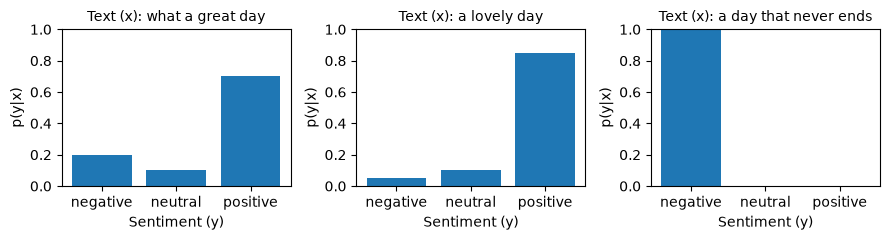

In [30]:
utils.ThreeWaySentimentExample.plot();

In [31]:
## We have a helper function you can use to draw 1 such plot
## try, for example, 
# utils.plot_pmf(['fiction', 'non-fiction'], [1/2, 1/2], title="The Argonauts by Maggie Nelson");

Another way to view pmfs is to stack the probability masses in order and use a single `barh` plot.

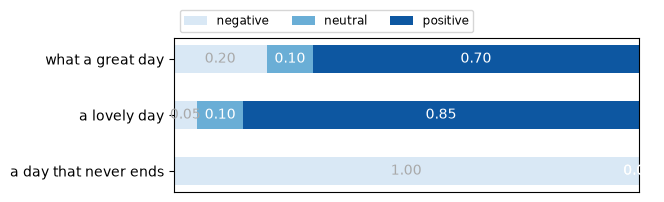

In [32]:
utils.ThreeWaySentimentExample.plot(stacked_bars=True);

In [33]:
## We have a helper function you can use to draw such plots
## try, for example, 
# utils.plot_pmfs_barh(
#     # predict the pmfs of these texts
#     pmfs={"The Argonauts by Maggie Nelson": [1/2, 1/2], "Foundations of Language": [0., 1.]},
#     category_names=['fiction', 'non-fiction']
# );

Some papers and textbooks refer to a collection of pmfs as a 'table'. That's because you can also imagine the row vector of $K$ probability masses specific to each condition being stacked for various distinct conditions. 

Example: suppose we are working with 3-way sentiment classification, with $c_1$ for negative, $c_2$ for neutral and $c_3$ for positive sentiment, and let's consider 3 example inputs in English. You could argue that the box `ML sorcery` is doing something  to the effect of table look-up using a data structure of the following kind:

In [34]:
example_pmfs = {
    "what a great day": np.array([0.2, 0.1, 0.7]),
    "a lovely day": np.array([0.05, 0.1, 0.85]),
    "a day that never ends": np.array([1., 0., 0.])
}
print(utils.pmfs_to_str(example_pmfs))

x                        p(1|x)    p(2|x)    p(3|x)
---------------------  --------  --------  --------
what a great day           0.2        0.1      0.7
a lovely day               0.05       0.1      0.85
a day that never ends      1          0        0


The condition $x$ can be imagined as the key to an indexing mechanism (here realised by a python dict); locating the row that's specific to the condition gives us the $K$-dimensional row vector of probabilities we mean to work with. If you call the entire table $\boldsymbol{\theta}$, and you use $\boldsymbol{\theta}^{(x)}$ to denote the vector specific to a condition $x$, then you can define the condition-specific pmf as $p_{\boldsymbol{\theta}}(k|x) = \theta^{(x)}_k$; for `a great day` then we have $\boldsymbol\theta^{(\text{a great day})} = (0.2, 0.1, 0.7)^\top$, hence the probability that $Y=c_3$ under this conditional pmf is $p_{\boldsymbol{\theta}}(3|\text{a great day}) = \theta^{(\text{a great day})}_3 = 0.7$. It is in this sense that conditional pmfs can be imagined or regarded as tables, and assessing conditional probabilities can be regarded as table lookup. 

*Terminology note:* in probabilistic graphical models literature (e.g., [Koller's textbook on PGMs](https://mitpress.mit.edu/9780262013192/probabilistic-graphical-models/)) you will find the term _tabular conditional probability distributions_ (or _tabular CPDs_) to refer to essentially this kind of representation. 

In [35]:
class TabularModel(ProbabilisticModel):

    def __init__(self, pmfs: dict):
        """
        """
        self.num_classes = utils.infer_num_classes(pmfs)        
        self.pmfs = pmfs

    def __call__(self, x: str) -> 'np.array':
        pmf = self.pmfs.get(x, None)
        if pmf is None:
            raise ValueError(f"I do not know a pmf for: {x}")
        return pmf

M = TabularModel(example_pmfs)
print("what a great day -->", M("what a great day"))

what a great day --> [0.2 0.1 0.7]


In [36]:
# You might want to play with M a bit

At this point our sketch for a text classifier has a box labelled `ML sorcery`. We called it this way to draw your attention to the fact that, even though we can  _regard_ a conditional pmf as if we indeed had a table, the table is often only a handy metaphor. In some classic 90s models the table is indeed the tool we use to represent (and even estimate our models), but the actual mapping $p$ from any given $x$ to the conditional probability masses for the different outcomes of the target variable is entirely open to our creativity. In modern instances, the mapping is a piece of machine learning technology such as a log-linear model or a neural network.

Now, there are a number of questions that need to be answered:
* How do we go from text to probabilities by means other than some crude table lookup? More technically: how do we parameterise pmfs flexibly?
* Where do probabilities come from? More technically: how do we estimate the parameters of our model?

And we will get to those. But you might also have noticed that when we first illustrated text classification the output was a class. How do  we go from probabilities for possible classes to an actual class? Well, we make a _decision_ by following a recipe or _decision rule_.

## Decision Rule

A _decision rule_ is a recipe for predicting a single outcome on the basis of the probability masses of all possible outcomes, that is, it maps from a pmf $p(k|x)$ to a single outcome $\hat y$. 

```mermaid
flowchart LR

C["$$p(1|x), \ldots, p(K|x)$$"] --> D(decision rule) --> E["$$\hat{y}~$$"]
```


In [37]:
class DecisionRule:
    """
    This class outputs a decision by searching through a given pmf via the method __call__.
    """

    def __call__(self, pmf: 'np.array') -> int:
        """Return the chosen outcome (int) out of those available in the support of the pmf"""
        raise NotImplementedError("Concrete implementations will be discussed later")

In NLP the most common decision rule is the _most probable class_ rule which outputs the _mode_ of the conditional distribution:
$$\hat y = \arg\,\max_{c_k\in \mathcal Y}~p(k|x)$$
That is, we regard the class that is assigned highest probability by our model as in some sense **the** prediction of the text classifier. This decision is a convention, and there is no strong theoretical argument for it. It is just a common practice, and it has worked well for many problems, for many years. (Though, in many contexts the cracks are obvious and we may need better tools; for example, in applications where mispredictions cause harm to users of automated systems, and in situations where the outcome space is structured, like in text generation. We will talk about those in due time.) 

In [38]:
class MostProbableClass(DecisionRule):
    """
    The 'most probable class' decision rule.
    """
    
    def __call__(self, pmf: 'np.array') -> int:
        return np.argmax(pmf)

D = MostProbableClass()
print("what a great day -->", D(M("what a great day")))

what a great day --> 2


So, in a technical sense the thing the model predicts for a condition $x$ really is the pmf. A better word for it is _prescribes_: the model prescribes the pmf. Another technical word for it is _parameterises_: the model parameterises the pmf. These are nice and clear ways to talk about it. In a conventional sense, the 'system' predicts the most probable class. So you can regard the 'system for text classification' as the combination of the _probabilistic model_ that maps $x$ to $p(k|x)$ for all $c_k\in \mathcal Y$ and the _decision rule_ that maps the pmf $p(\cdot|x)$ to a single predicted outcome $\hat y$.

```mermaid
flowchart LR

A[$$~x$$] --> B(probabilistic model) --> C["$$p(1|x), \ldots, p(K|x)$$"] --> D(decision rule) --> E["$$\hat{y}~$$"]
```

In [39]:
class TextClassifier:
    """
    A text classifier is able to map text (str) to a class (str), 
    we do so via the special method __call__.
    """

    def __init__(self, outcome_space: clslib.NamedClasses, model: ProbabilisticModel, decoder: DecisionRule):
        self.outcome_space = outcome_space
        self.model = model
        self.decoder = decoder
    
    def __call__(self, x: str) -> str:
        """Map input text x to a named category (str)"""
        pmf = self.model(x)
        index = self.decoder(pmf)
        return self.outcome_space.name(index)

In [40]:
S = TextClassifier(example_outcome_space, TabularModel(example_pmfs), MostProbableClass())
print("what a great day -->", S("what a great day"))

what a great day --> positive


Later in the course, we will talk more about decision rules. If you are eager to know more about alternatives, refer to section 1.5 of Bishop's _Pattern Recognition and Machine Learning_, where you can read about _expected loss minimization_ (or, equivalently, _expected utility maximization_). 

In the rest of this tutorial, we will look into how to design, estimate parameters for, and evaluate one such system. But, before we go on, reflect on the following questions.

## Questions

1. Suppose you take the tabular view as a literal representation of the mapping from possible inputs to conditional probabilities for each of $K$ classes. Now imagine that each cell of this table is treated as an independent parameter, with the only dependence across parameters being the fact that each row of this table must sum to 1. How many parameters do you expect to need in order to represent all probabilities that are relevant to a dataset of $N$ distinct texts? Explain how you got to your answer.
2. Continue with the sketch from question (1) above. Imagine that you have a statistical procedure to estimate the parameter values of each conditional probability from observed data (for example, you might use the observed sample frequency of an outcome in a certain context). Do you think your table is going to be rather sparse (lots of 0s and few 1s) or dense (generally very few 0s)? Why do you think that?
3. Continue whith the sketch from questions (1) and (2) above. If I have a new text (never seen before), can your table help me predict a class for it? Justify your answer.
4. Now, more generally, do you see why the literal treatment of conditional cpds as tables is not going to get us very far along NLP problems? What are the properties of text (or, more generally, of natural language) that makes it difficult to model with tables of conditional probabilities?
5. This last question concerns decision rules. Can you explain in your own words and give an example where the most probable class rule produces results that go against reasonable intuition?

## Text Representation

Let's return to our `ML sorcery` box 
```mermaid
flowchart LR

A[$$~x$$] --> B(ML sorcery) --> C["$$p(1|x), \ldots, p(K|x)$$"]
```
and consider what it's likely hiding from us. 

Focus for a moment on the output it produces: a K-dimensional vector of probability values that add up to 1 (the technical term here is a vector in the _probability simplex_). 
By now you must be at least minimally familiar with logistic regression, so let's imagine that whatever happens in the `ML sorcery` box must in some sense resemble logistic regression. In fact, it is a generalised form of regression that combines $K$ regressors (one per class) constrained to output probability masses that sum to one. Because the _softmax_ function has the property of mapping _any_ $K$ reals to a $K$-dimensional probability vector, let's assume that our regressor's outputs are softmax-transformed by design, and then let's call this component a _softmax regressor_. 

So our `ML sorcery` box contains something of this kind:
```mermaid
flowchart LR
X["$$\mathbf h(x)$$"] --> C(softmax regression) --> P["$$p(1|x), \ldots, p(K|x)$$"]
style X fill:transparent,stroke:0px,stroke-width:0px
```
where, softmax regression works with a *numerical, vector-valued* representation of the input text. This representation, which we denote by $\mathbf h(x) \in \mathbb R^D$, is a _point_, not a string, not a token sequence, but a point in a $D$-dimensional real coordinate space.

Of course, plain text **is not** a point in some fixed-dimensional real coordinate space, but it _can_ be represented as such, if we are willing to make some assumptions. Let's group all of the assumptions necessary for that into a new box and let's call it `encoder`. Here is a better view of our probabilistic model, now with `ML sorcery` replaced by two modules, an _encoder_ which represents input text as a point in a $D$-dimensional representation space and a _softmax regressor_, which maps that point to a $K$-dimensional normalised probability vector:
```mermaid
flowchart LR

A[$$~x$$] --> B(encoder) -->|"$$\mathbf h(x)$$"| C(softmax regression) --> P["$$p(1|x), \ldots, p(K|x)$$"]
```

In this tutorial, the encoder will be a combination of preprocessing transformations of the data. In later tutorials, the encoder will be an integral part of the _trainable_ component of the `ML sorcery` box, just like the softmax regressor is. Still, some of the ideas we will develop next remain useful even after we replace this crude encoder by something more interesting. 

In [41]:
class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")
        
class SoftmaxRegressor(ProbabilisticModel):

    def __init__(self, encoder: Encoder):
        self.encoder = encoder

    def __call__(self, x: str) -> 'np.array':
        h = self.encoder(x)
        raise NotImplementedError("We will get there...")        

With the assistance of a _tokenizer_, we now turn to the _encoder_ block.

### Named Axes

A simple way to construct a representation space is to imagine that each dimension (or axis) of the representation space captures a specific named pattern or _feature_ of the text. For example, you might name the first dimension `has: good` and use $h_1(x) = 1$ to indicate that `good` occurs in $x$ and $h_1(x) = 0$ to indicate that it does not occur in $x$. You might name the second dimension `has: not ... good` and use $h_2(x) = 1$ to indicate that the pattern `not ... good` occurs in $x$, perhaps with any number of words in between `not` and `good`, and so on. Your creativity is the limit. Well, your creativity, _and_ the size of the space (number of dimensions), _and_ your ability to indeed detect the pattern. For example, detecting syntactic voice (passive or active) is relatively difficult and language-specific, hence using this for text representation, though useful for many tasks, is not easy.

Below we demonstrate the intuition, with a crude blank-based tokeniser and a very simple representation space.

In [42]:
from tabulate import tabulate
from collections import OrderedDict

class ToyEncoder(Encoder):

    def __init__(self, vocab: list):
        """
        This toy encoder has one dimension for each symbol in 'vocab'. 
        These known 'words' are detected by exact string matching against the tokens returned by string.split().
        """
        self._vocab = tuple(vocab)
    
    def __len__(self):
        """Number of dimensions"""
        return len(self._vocab) 

    def coords(self):
        """The mnemonic labels for the axes are the words in the vocabulary"""
        return [f"'{w}' in x" for w in self._vocab]

    def __call__(self, x):
        """
        Our toy encoder employs a crude tokeniser (ie, python's string.split method) 
        and detects the presence in x of the words in its vocabulary.
        Detection is based on string matching, after lowercasing.
        """
        tokens = [t.lower() for t in x.split()]
        return np.array([1 if w in tokens else 0 for w in self._vocab])        
        
toy_enc = ToyEncoder(['good', 'bad'])

print(utils.encodings_to_str(
        {text: toy_enc(text) for text in ["a good day", "a bad day", "not a bad day", "a regular day", "a strange day"]},
        toy_enc.coords()
    )
)

x                h_0(x): 'good' in x    h_1(x): 'bad' in x
-------------  ---------------------  --------------------
a good day                         1                     0
a bad day                          0                     1
not a bad day                      0                     1
a regular day                      0                     0
a strange day                      0                     0


In [43]:
# You might want to play a bit with toy_enc. 
# See for example what it does to texts like "a GOOD day" and "a goooooood day". 

### Questions

Suppose you have access to a tokenizer and imagine that you define a representation space using the idea of _named axes_ introduced above. Concretely, your space has a dimension for each of the $V$ symbols in the vocabulary of your tokenizer (if your tokenizer is rule based and does not have a closed vocabulary, you can consider $V$ to be number of unique tokens in some large corpus _after_ tokenization using your tokenizer) and that you use each dimension then to capture the number of times the corresponding token occurs in the text being represented. 

1. For a given text $x$, what is the dimensionality of $\mathbf h(x)$?
2. Does the dimensionality of $\mathbf h(x)$ depend on $x$ and if so does it depend on a specific property of $x$ (such as its length)?
3. In this representation space, can we distinguish `'man bites dog'` (tokenized as `['man', 'bites', 'dog']`) from `'dog bites man'` (tokenized as ['dog', 'bites', 'man'])?
4. If your tokenizer were a BPE tokenizer, would your answer to the previous question be different?
5. Now suppose you redefine your representation space such that each dimension is now labelled with a _pair_ of adjacent tokens and is now used to count the number of times the corresponding pair of adjacent tokens occurs in the text being represented. Respond the same four questions above, but in relation to this new space.

The representation spaces you worked out are in fact classics of NLP. The first one is the so-called _bag of words_ representation, called this way because you can imagine the representation of a text in this space as the mathematical equivalent of i) writing the text on a piece of paper, ii) chopping the paper according to your tokenization procedure, and iii) putting the resulting pieces of paper in a bag. The second one is the so-called _bag of bigrams_ representation.

## Log-Linear Softmax Regression

> This section reviews logistic regression, a form of softmax regression where data and parameters interact linearly, but our review is rather compact. If you feel like you need more laboured explanations, you might want to check [Chapter 4 of SLP3](https://web.stanford.edu/~jurafsky/slp3/4.pdf), though be aware that its treatment of the topic is rather extensive, hence, if you go that way, do plan enough time for it, alternatively, you may consult a reference text such as Bishop's textbook (though with SLP3 the advantage is that the exposition already focus on NLP).

Now that we have vector-valued and fixed-dimensional text representations, let's open up the _softmax regression_ box 
and, for now, let's start with a log-linear softmax regressor. 
```mermaid
flowchart LR
X["$$\mathbf h(x)$$"] --> C(log-linear softmax regression) --> P["$$p(1|x), \ldots, p(K|x)$$"]
style X fill:transparent,stroke:0px,stroke-width:0px
```
When $K=2$, this is commonly known as _logistic regression_. To avoid confusion, in this section we use the more verbose term: log-linear softmax regression. 

A softmax regressor of the log-linear kind maps any $D$-dimensional input $\mathbf h(x)$ to a $K$-dimensional normalised probability vector (the technical term here is a vector in the _probability simplex_) by $K$ linear transformations followed by the softmax function:
```mermaid
flowchart LR

X["$$\mathbf h(x)$$"] --> C(linear model)
style X fill:transparent,stroke:0px,stroke-width:0px
C -->|"$$\mathbf w_1^\top\mathbf h(x) + b_1$$"| S1["$$s_1(x)$$"]
C -.-> S2["$$\ldots$$"]
style S2 fill:transparent,stroke:0px,stroke-width:0px
C -->|"$$\mathbf w_K^\top\mathbf h(x) + b_K$$"| S3["$$s_K(x)$$"]
S1 & S2 & S3 --> F(softmax) --> P["$$p(1|x), \ldots, p(K|x)$$"]
```

The model is _log-linear_ because the data representation $\mathbf h(x)$ and the model's trainable parameters interact linearly to form the so-called _linear predictors_ $s_1(x), \ldots, s_K(x)$. These linear predictors, also called _scores_ or _logits_, depending on the author's taste, are defined as follows:
\begin{equation}
s_k(x) = \mathbf w_k^\top \mathbf h(x) + b_k ~.
\end{equation}
They are, in turn, mapped to a $K$-dimensional probability vector via the softmax transformation:
```mermaid
flowchart LR

S["$$s_1(x), \ldots, s_K(x)$$"]
S --> F(softmax) --> P["$$\frac{\exp(s_1(x))}{\sum_{i=1}^K \exp(s_i(x))}, \ldots, \frac{\exp(s_K(x))}{\sum_{i=1}^K \exp(s_i(x))}$$"]
```
Therefore, the log-linear softmax regressor prescribes the probability mass of $c_k$ given $x$ as:
\begin{equation}
p(k|x) = \frac{\exp(s_k(x))}{\sum_{i=1}^K \exp(s_i(x))} = \frac{\exp(\mathbf w_k^\top\mathbf h(x) + b_k)}{\sum_{i=1}^K \exp(\mathbf w_i^\top\mathbf h(x) + b_i)}
\end{equation}

The trainable parameters of the model are the class-specific vectors and the class-specific biases: $\boldsymbol\theta = \{\mathbf w_1, \ldots, \mathbf w_K, b_1, \ldots, b_K\}$ with $\mathbf w_k \in \mathbb R^D$ and $b_k \in \mathbb R$. In fact, it's very common to turn the vectors into row vectors and stack them into a KxD matrix, and to stack the biases together into a K-dimensional vector, the result is a matrix of weights $\mathbf W \in \mathbb R^{K \times D}$ and a vector of biases $\mathbf b \in \mathbb R^K$. Then we can re-express the $K$ log-linear transformations as $\operatorname{softmax}(\mathbf W \mathbf h + \mathbf b)$.

The parameters of any such model are estimated to fit the available training data, which can be done in a number of ways. For example, given a dataset of observations, we can estimate model parameters via maximum likelihood estimation (MLE) using, for example, a gradient-based optimiser. 

Below, we illustrate how the model works in code. Note that for that we assume the parameters are already known and specified via the constructor of the model class.

In [44]:
import scipy
from scipy.special import softmax

class LogLinearSoftmaxRegressor(ProbabilisticModel):

    def __init__(self, encoder: Encoder, W: 'np.array', b: 'np.array'):
        """
        encoder: turns a text (str) into a D-dimensional vector
        W: KxD matrix of weights
        b: B-dimensional vector of weights
        """
        self.encoder = encoder
        assert W.shape[0] == len(b), f"The matrix W should have shape KxD with K={len(b)}"
        assert W.shape[1] == len(encoder), f"The matrix W should have shape KxD with D={len(encoder)}"
        self.W = W
        self.b = b
        
    def __call__(self, x: str) -> 'np.array':
        h = self.encoder(x) # D features
        s = np.dot(self.W, h) + self.b # K linear predictors
        pmf = softmax(s) # K probabilities
        return pmf

We can demonstrate how this works with a toy regressor for our toy 2-dimensional encoder and with made-up parameter values.

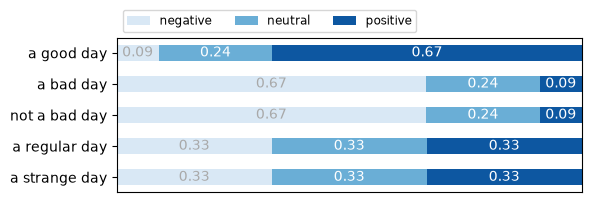

In [45]:
toy_sr = LogLinearSoftmaxRegressor(
    encoder=ToyEncoder(['good', 'bad']), 
    # KxD
    W=np.array([[-1., 1.], [0., 0.], [1, -1.]]), 
    # K
    b=np.array([0., 0., 0.])
)

# and we can visualise the predicted pmfs using t1lib's horizontal, stacked bar plot
utils.plot_pmfs_barh(
    # predict the pmfs of these texts
    pmfs={text: toy_sr(text) for text in ["a good day", "a bad day", "not a bad day", "a regular day", "a strange day"]},     
    category_names=example_outcome_space.names
);

In [46]:
# You may want to play with toy_sr, for example to see what it does to other texts

### Questions

The log-linear softmax regressor somehow deals with a clear limitation of a crude, tabular model based on table look-up, namely, it is able to associate _any_ text (seen or unseen) with a corresponding pmf. 

1. Describe in your words what is the key difference in design that allows for such a thing.
2. Suppose that for a given choice of representation space and a given criterion of optimality, you can indeed determine the _best possible_ parameter values for the model. Even with the best possible parameters, the softmax regressor can produce pmfs that are essentially uninformed or which violate reasonable expectations (for example, producing similar pmfs to texts that express opposite sentiments). Explain in your words why that's possible.

# Experiment

In this section we will develop a system for the classification of news articles into one of 4 pre-defined topics (`world`, `sports`, `business` and `tech/sci-fi`).  

In [47]:
agnews_outcome_space = clslib.NamedClasses(['world', 'sports', 'business', 'tech/sci-fi'])
print(agnews_outcome_space)

0: world, 1: sports, 2: business, 3: tech/sci-fi


## Data

We will use the AG corpus, a collection of more than 1 million news articles. News articles have been gathered from more than 2000 news sources by ComeToMyHead in more than 1 year of activity. ComeToMyHead is an academic news search engine which has been running since July, 2004. 

> Xiang Zhang, Junbo Zhao, Yann LeCun. [Character-level Convolutional Networks for Text Classification.](https://proceedings.neurips.cc/paper_files/paper/2015/file/250cf8b51c773f3f8dc8b4be867a9a02-Paper.pdf) Advances in Neural Information Processing Systems 28 (NeurIPS 2015).


Learn more [here](https://huggingface.co/datasets/fancyzhx/ag_news?utm_source=chatgpt.com).


In [48]:
from tqdm.notebook import tqdm
from datasets import load_dataset

#Loading our training corpus
dataset = load_dataset("fancyzhx/ag_news") 
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


Have a look at some training examples:

In [49]:
#An example of an article from our training corpus
print("Text:", dataset["train"]["text"][0])
print("Gold label (id):", dataset["train"]["label"][0])
print("Gold label (name):", agnews_outcome_space.name(dataset["train"]["label"][0]))

Text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
Gold label (id): 2
Gold label (name): business


In [50]:
corpus = dataset["train"]["text"]

## Fitting a BPE tokenizer

> Even though we packaged an implementation of BPE training and segmentation in `bpe` for didactic purposes, here we will turn to a more widely used (and hence tested) implementation (this is good practice!) from the `tokenizers` library by Hugging Face.

A BPE tokenizer has some _hyperparameteres_ which we need to decide upon, most notably `vocab_size` (this is related to the number of merges) and `min_frequency` (so merge operations are performed only for sufficiently frequent pairs) and the `pre-tokenization` strategy necessary before we can merge. Though the pre-tokenization strategy is a hyperparameter, in this tutorial we will treat it as a fixed option (we will be using the library's `Metaspace` strategy, which is the closest to that of the textbook; essentially, white space is replaced by as a special unicode character that looks a lot like `_` and pre-tokenization then segments the string before any occurrence of this character).

In [51]:
vocab_size = 1000
min_frequency = 2

In [52]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Metaspace

def train_tokenizer(corpus, vocab_size, min_frequency, pretokenizer=Metaspace()):
    """
    corpus: a list of texts (each a string)
    vocab_size: number of distinct BPE tokens
    min_frequency: we only merge token pairs that are frequent enough
    pretokenizer: a simple tokenizer that we use before BPE tokenization
    
        You probably don't need to change the pretokenizer, unless you are working with
        languages that really don't use any form of blank space 
        (then you could, for example, pretokenize at character level)
    """
    # Create an empty BPE tokenizer
    tokenizer = Tokenizer(BPE(unk_token="[UNK]")) #unk_token used for characters that cannot be encoded

    # First split the corpus into words
    tokenizer.pre_tokenizer = pretokenizer

    # Tell BPE how large the vocabulary should be
    trainer = BpeTrainer(
        vocab_size=vocab_size, # The size of the vocabulary to learn.
        min_frequency=min_frequency, # Only perform a merge if the pair occurs at least min_frequency times in the training corpus.
        special_tokens=["[UNK]"]
    )

    # Learn the vocabulary and merge rules
    tokenizer.train_from_iterator(corpus, trainer=trainer)

    return tokenizer

In [53]:
tokenizer = train_tokenizer(corpus, vocab_size, min_frequency)

Save the trained tokenizer

In [54]:
tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

We have now trained our tokenizer. You can inspect already the resulting vocabulary:

In [55]:
vocab = tokenizer.get_vocab()
print(vocab)

{'▁v': 243, 'ex': 392, '▁Air': 825, '▁Intern': 575, '▁one': 513, '▁top': 872, '▁Amer': 608, 'ica': 881, '▁pre': 743, 'own': 410, 'ise': 636, 'e': 60, 'een': 898, '▁Cl': 832, 'ort': 522, 'ment': 279, '▁Comm': 988, 'etw': 534, 'ook': 631, '▁may': 802, '-s': 776, 'vel': 593, '▁Saturday': 745, '▁Internet': 826, 'ational': 504, '▁announ': 677, 'aj': 775, '▁Ph': 897, '7': 21, '▁will': 305, 'ton': 594, '▁The': 214, 'aw': 490, '▁M': 130, '▁e': 161, '▁were': 564, '▁bu': 683, 'ool': 969, '▁Or': 799, '▁prod': 778, '▁security': 879, 'J': 37, 'old': 355, '▁its': 234, 'istan': 878, 'esterday': 545, 'less': 849, ',000': 887, 'ose': 627, '▁I': 135, 'act': 453, '▁Jo': 870, '▁world': 588, '/': 13, 'oo': 273, 'ict': 507, 'els': 910, '▁pro': 223, 'ball': 779, '▁(Reuters': 327, 'ot': 152, 'rop': 444, '▁T': 126, 'ian': 238, '▁sl': 671, 'pl': 586, '▁which': 689, '▁tal': 902, 'ations': 497, 'ling': 995, 'C': 30, '▁co': 704, 'ist': 278, 'ics': 757, 'orld': 713, '▁Olymp': 973, 'rit': 471, '▁wor': 337, 'rough': 

## Tokenizing

Here we tokenize an example from the test set.

In [56]:
corpus_testing = dataset["test"]["text"]
corpus_testing[0]

"Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul."

In the Hugging Face library, tokenization is achieved by a method called `encode` (not to be confused with the role of the `Encoder` block of our text classifier). The method returns a structured object containing the token sequence, see below:

In [57]:
%%time
# Try it out
output = tokenizer.encode(corpus_testing[0])

print(output.tokens)  # you can work with the string tokens
print(output.ids)     # or with the 0-based integer ids

['▁F', 'ear', 's', '▁for', '▁T', '▁N', '▁p', 'ens', 'ion', '▁after', '▁tal', 'ks', '▁Un', 'ions', '▁re', 'pr', 'es', 'ent', 'ing', '▁work', 'ers', '▁at', '▁T', 'urn', 'er', '▁', '▁', '▁New', 'all', '▁say', '▁they', '▁are', '▁', "'", 'd', 'is', 'app', 'oin', 'ted', "'", '▁after', '▁tal', 'ks', '▁with', '▁str', 'ick', 'en', '▁p', 'ar', 'ent', '▁fir', 'm', '▁F', 'ed', 'eral', '▁M', 'og', 'ul', '.']
[159, 199, 74, 146, 126, 158, 106, 411, 122, 325, 902, 232, 403, 379, 154, 750, 89, 133, 102, 758, 163, 201, 126, 532, 85, 82, 82, 399, 237, 819, 569, 365, 82, 6, 59, 109, 853, 538, 308, 6, 325, 902, 232, 211, 607, 354, 95, 106, 96, 133, 334, 68, 159, 94, 610, 130, 405, 207, 12]
CPU times: user 324 μs, sys: 123 μs, total: 447 μs
Wall time: 608 μs


## Loading, preparing and pre-processing data

In this section, we load the training data (texts and labels) and split them into *k* folds (for cross validation; remember ML1?).

And then, we can split the pairs into *k* folds for parameter estimation and evaluation. We keep the test set completely unseen.

In [58]:
%%time
my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        utils.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

CPU times: user 1.33 s, sys: 28.4 ms, total: 1.36 s
Wall time: 1.38 s


## Representing articles via token indicators

We turn the textual documents into a vector representation with as many dimensions as the BPE vocabulary size. If a token appears in the document, its corresponding dimension's value is 1, otherwise 0. (Note that this space is as large as that of a bag-of-words representation, but the coordinates do not count occurrences they just flag presence.)

In [59]:
class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [60]:
token_indicator_encoder = TokenIndicator(tokenizer)
doc_repr = token_indicator_encoder(corpus[0])
print(len(doc_repr))
print(doc_repr.sum())

1000
51.0


In [61]:
# You might want to play with token_indicator_encoder

## Training a log-linear softmax regressor with scikit-learn

Here we put together some code to train a log-linear softmax regressor using scikit-learn's implementation of `LogisticRegression` (scikit-learn calls it logistic regression independently of the number of classes to be produced; don't be too bothered by these different conventions, this happens more than you could count.)

You might have noticed that our representation spaces are rather large and that any one document's encoding will have relatively few non-zero coordinates. To handle these _sparse_ vectors, we rely on a special data structure from scipy (namely, `csr_matrix`). Study the function `loglin.fit` before continuing.

In [62]:
%%time
# train using the first fold (less than 1 min)
# (don't mind the warning about convergence)
logistic_model = loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)  # remember to index datasets by [run][fold]

CPU times: user 33.6 s, sys: 835 ms, total: 34.4 s
Wall time: 35.1 s


/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


## Predictions

The model is now trained. We can make predictions for new sentences given our trained model. Study the function `loglin.predict` before continuing.

In [63]:
%%time
# for the model trained on the first fold (less than 10s)
logistic_predictions = loglin.predict([text for text, gold_label in my_cross_validation_sets[0][0]["validation"]], logistic_model, token_indicator_encoder)  # remember to index datasets by [run][fold]

CPU times: user 6 s, sys: 213 ms, total: 6.22 s
Wall time: 6.47 s


## Assessing the performance of the model

Given the predictions of the model, we can assess how well these algn with the actual labels. We measure the accuracy between the gold-labels and the model's predictions:

In [64]:
%%time
from sklearn.metrics import accuracy_score

# again, for the model trained on the first fold 
logistic_accuracy = accuracy_score(
    [gold_label for text, gold_label in my_cross_validation_sets[0][0]["validation"]],  # remember to index datasets by [run][fold]
    logistic_predictions
)
print(f"Accuracy: {logistic_accuracy:.4f}")

Accuracy: 0.8556
CPU times: user 4.59 ms, sys: 1.06 ms, total: 5.65 ms
Wall time: 4.99 ms


## Cross validation

We implemented a full cross-validation experiment in `utils.cross_validation_experiment`, have a look at it, specifically, the `if` block that concerns the `logistic` model option.

Then, let's test it for our model.

In [65]:
%%time
my_classifiers = OrderedDict()

my_classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        utils.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run], 
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


CPU times: user 3min 16s, sys: 5.23 s, total: 3min 21s
Wall time: 3min 24s


Here's a nice way to visualise accuracies:

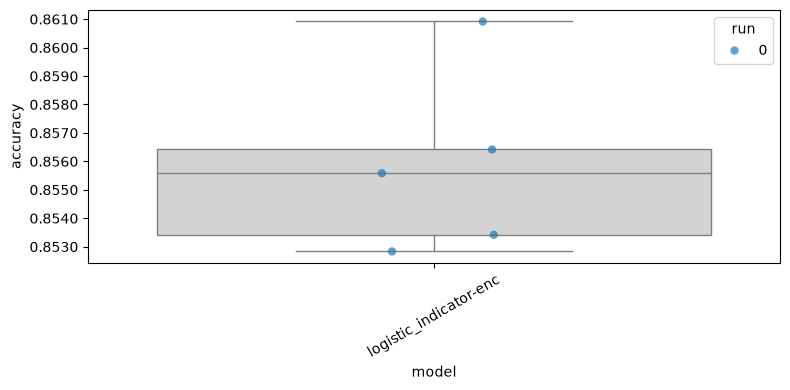

In [66]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

### Questions

1. Do you think accuracy is a good metric to assess the performance of our model? Justify your choice using a property of the dataset. 
2. Suppose it's not, do you know an alternative? 

## Improving the model

There are various experimental design decisions that can improve performance at text classification.

On the text representation side of things, changing the tokenizer (for example, by experimenting with BPE's hyperparameters, such as vocabulary size) might lead to units that are more or less informative. We may also change the space in which the texts are represented given a specific trained tokenizer. For example, we currently use token indicators; what if we use token counts or frequencies?

When NLP models are built out of better text representations, their performance in downstream tasks can also substantially improve. 

The architecture of the probability model may also affect the quality of the classifier. For example, one can use a non-linear function (e.g., a neural network) to predict the logits of the softmax regressor. 

We explore some of these ideas next.

### Exercise: Bag-of-Words Encoding

Like we described before, a bag-of-words representation of $x$ is informative of _which_ tokens occur in $x$ and _how many times_ each of those tokens occurs in $x$. 

**Exercise**

Implement a bag-of-words encoder and test a model that uses it.

In [67]:
class BagOfWords(Encoder):

    pass

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/waziz/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


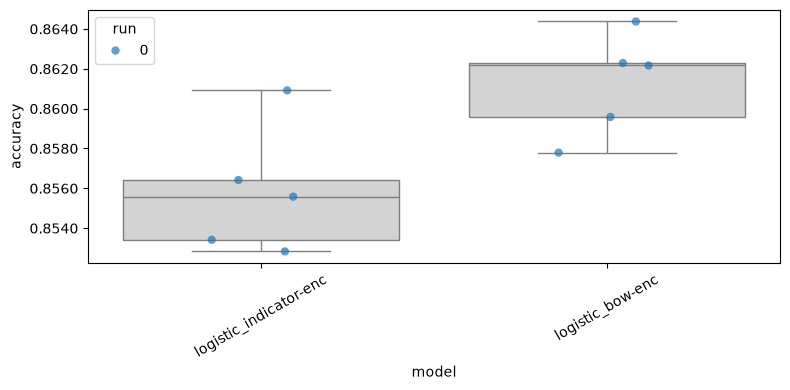

In [68]:
try:
    from part1 import solutions
except ImportError:
    print("You need your own implementation")
else:
    my_classifiers['logistic_bow-enc'] = []
    for run, seed in enumerate(my_seeds):    
        run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
        my_classifiers['logistic_bow-enc'].append(
            solutions.cross_validation_experiment_with_bow_encoder(
                data_splits=my_cross_validation_sets[run],
                tokenizer=tokenizer,
                model_option='logistic',
                save_to=run_folder,
                loglin_args={
                    'max_iter': 100
                }
            )
        )    
    analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In our own implementation, we observe a small increase in average performance, and hopefully you do too.  
Do you have an intuition as to why?

### Deeper softmax regressor

Let's explore a change in the model architecture, with a non-linear (NN-based) transformation of the document features, as shown in the following sketch:

```mermaid
flowchart LR

X["$$\mathbf h(x)$$"] --> A("linear (H outputs)")
A --> B(ReLU)
B --> C("linear (K outputs)") 
C -->|"$$s_1(x), \ldots,s_K(x)$$"| F(softmax) 
F --> P["$$p(1|x), \ldots, p(K|x)$$"]
```

We implement this model using _torch_ (remember DL1?). You can find it in `smlp` (the _s_ in _smlp_ is for _sparse_, as we implemented an MLP that can handle sparse inputs; this makes the tutorial more CPU friendly). You don't necessarily need to learn all the details in there, as those are mostly DL1 skills. But, it might be worth to analyse the model architecture: see `smlp.SparseMLP`. You will see that except for the torch look and the additional hidden layer, it is quite similar to our log-linear softmax regressor from earlier sections.

Here's how you can train the model using one of the folds.

In [69]:
%%time
import smlp

# about 2 minutes
metrics_for_all, best_epoch, best_preds = smlp.train_neural_network_model(
    my_cross_validation_sets[0][0]["training"],  # remember to index datasets by [run][fold]
    my_cross_validation_sets[0][0]["validation"],  # remember to index datasets by [run][fold]
    token_indicator_encoder, 
    save_to=f'{results_folder}/tmpmodel',
    hidden_dim=128, 
    dropout=0.1, 
    batch_size=64, 
    learning_rate=1e-4, 
    weight_decay=1e-4, 
    num_epochs=10
)

Transforming documents...
Document transformation done! Time taken: 27.626 seconds
Dataloader done! Time taken: 1.095 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

/Users/waziz/github/nlp1-code/part1/smlp.py:57: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:256.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/Users/waziz/github/nlp1-code/part1/smlp.py:60: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/Context.cpp:767.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.7565 | train acc: 0.7484 | val loss: 0.4793 | val acc: 0.8382
Epoch 02 | train loss: 0.4545 | train acc: 0.8441 | val loss: 0.4286 | val acc: 0.8502
Epoch 03 | train loss: 0.4198 | train acc: 0.8524 | val loss: 0.4139 | val acc: 0.8537
Epoch 04 | train loss: 0.4044 | train acc: 0.8566 | val loss: 0.4056 | val acc: 0.8558
Epoch 05 | train loss: 0.3937 | train acc: 0.8599 | val loss: 0.4003 | val acc: 0.8562
Epoch 06 | train loss: 0.3856 | train acc: 0.8631 | val loss: 0.3967 | val acc: 0.8575
Epoch 07 | train loss: 0.3791 | train acc: 0.8657 | val loss: 0.3933 | val acc: 0.8578
Epoch 08 | train loss: 0.3720 | train acc: 0.8672 | val loss: 0.3899 | val acc: 0.8576
Epoch 09 | train loss: 0.3658 | train acc: 0.8696 | val loss: 0.3868 | val acc: 0.8589
Epoch 10 | train loss: 0.3587 | train acc: 0.8711 | val loss: 0.3828 | val acc: 0.8607
Training done! Time taken: 62.001 seconds
CPU times: user 1min 26s, sys: 4.63 s, total: 1min 31s
Wall time: 1min 31s


In [70]:
#Statistics for the best epoch
best_epoch_metrics = metrics_for_all[best_epoch]
print(f"Best epoch: {best_epoch}")
print(f"Train metrics: {best_epoch_metrics['train_metrics']}")
print(f"Validation metrics: {best_epoch_metrics['val_metrics']}")

Best epoch: 9
Train metrics: {'loss': 0.3586991508404414, 'accuracy': 0.8710520833333333}
Validation metrics: {'loss': 0.3828299295504888, 'accuracy': 0.8607083333333333}


Let's do a full cross validation experiment using the token indicator encoder. Before continuing, have a look at `utils.cross_validation_experiment`, this time inspect the `if` block that concerns `model_option == 'mlp'`.

In [71]:
%%time
my_classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    my_classifiers['mlp_indicator-enc'].append(
        utils.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-4, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 27.481 seconds
Dataloader done! Time taken: 1.301 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7496 | train acc: 0.7550 | val loss: 0.4765 | val acc: 0.8391
Epoch 02 | train loss: 0.4539 | train acc: 0.8434 | val loss: 0.4266 | val acc: 0.8510
Epoch 03 | train loss: 0.4195 | train acc: 0.8528 | val loss: 0.4117 | val acc: 0.8548
Epoch 04 | train loss: 0.4043 | train acc: 0.8574 | val loss: 0.4047 | val acc: 0.8555
Epoch 05 | train loss: 0.3946 | train acc: 0.8605 | val loss: 0.4000 | val acc: 0.8570
Epoch 06 | train loss: 0.3851 | train acc: 0.8628 | val loss: 0.3983 | val acc: 0.8559
Epoch 07 | train loss: 0.3782 | train acc: 0.8652 | val loss: 0.3938 | val acc: 0.8577
Epoch 08 | train loss: 0.3717 | train acc: 0.8674 | val loss: 0.3907 | val acc: 0.8582
Epoch 09 | train loss: 0.3647 | train acc: 0.8693 | val loss: 0.3870 | val acc: 0.8597
Epoch 10 | train loss: 0.3577 | train acc: 0.8723 | val loss: 0.3844 | val acc: 0.8606
Training done! Time taken: 55.623 seconds
Transforming documents...
Document transformation done! Time taken: 26.583 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

...

Epoch 01 | train loss: 0.7570 | train acc: 0.7509 | val loss: 0.4809 | val acc: 0.8375
Epoch 02 | train loss: 0.4562 | train acc: 0.8416 | val loss: 0.4252 | val acc: 0.8536
Epoch 03 | train loss: 0.4214 | train acc: 0.8528 | val loss: 0.4083 | val acc: 0.8585
Epoch 04 | train loss: 0.4047 | train acc: 0.8573 | val loss: 0.4015 | val acc: 0.8599
Epoch 05 | train loss: 0.3952 | train acc: 0.8594 | val loss: 0.3981 | val acc: 0.8604
Epoch 06 | train loss: 0.3867 | train acc: 0.8620 | val loss: 0.3932 | val acc: 0.8627
Epoch 07 | train loss: 0.3796 | train acc: 0.8644 | val loss: 0.3899 | val acc: 0.8640
Epoch 08 | train loss: 0.3728 | train acc: 0.8667 | val loss: 0.3867 | val acc: 0.8651
Epoch 09 | train loss: 0.3653 | train acc: 0.8680 | val loss: 0.3846 | val acc: 0.8656
Epoch 10 | train loss: 0.3585 | train acc: 0.8711 | val loss: 0.3807 | val acc: 0.8676
Training done! Time taken: 62.258 seconds
Transforming documents...
Document transformation done! Time taken: 28.900 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7519 | train acc: 0.7544 | val loss: 0.4846 | val acc: 0.8384
Epoch 02 | train loss: 0.4541 | train acc: 0.8428 | val loss: 0.4327 | val acc: 0.8487
Epoch 03 | train loss: 0.4186 | train acc: 0.8536 | val loss: 0.4186 | val acc: 0.8521
Epoch 04 | train loss: 0.4036 | train acc: 0.8577 | val loss: 0.4105 | val acc: 0.8540
Epoch 05 | train loss: 0.3939 | train acc: 0.8604 | val loss: 0.4063 | val acc: 0.8542
Epoch 06 | train loss: 0.3860 | train acc: 0.8634 | val loss: 0.4042 | val acc: 0.8560
Epoch 07 | train loss: 0.3794 | train acc: 0.8653 | val loss: 0.4002 | val acc: 0.8557
Epoch 08 | train loss: 0.3727 | train acc: 0.8670 | val loss: 0.3969 | val acc: 0.8565
Epoch 09 | train loss: 0.3669 | train acc: 0.8696 | val loss: 0.3943 | val acc: 0.8571
Epoch 10 | train loss: 0.3596 | train acc: 0.8706 | val loss: 0.3918 | val acc: 0.8578
Training done! Time taken: 63.189 seconds
Transforming documents...
Document transformation done! Time taken: 27.154 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7432 | train acc: 0.7547 | val loss: 0.4855 | val acc: 0.8347
Epoch 02 | train loss: 0.4519 | train acc: 0.8436 | val loss: 0.4350 | val acc: 0.8468
Epoch 03 | train loss: 0.4172 | train acc: 0.8540 | val loss: 0.4205 | val acc: 0.8517
Epoch 04 | train loss: 0.4033 | train acc: 0.8575 | val loss: 0.4143 | val acc: 0.8528
Epoch 05 | train loss: 0.3933 | train acc: 0.8608 | val loss: 0.4089 | val acc: 0.8534
Epoch 06 | train loss: 0.3848 | train acc: 0.8622 | val loss: 0.4052 | val acc: 0.8540
Epoch 07 | train loss: 0.3783 | train acc: 0.8649 | val loss: 0.4023 | val acc: 0.8555
Epoch 08 | train loss: 0.3722 | train acc: 0.8671 | val loss: 0.3987 | val acc: 0.8555
Epoch 09 | train loss: 0.3653 | train acc: 0.8695 | val loss: 0.3957 | val acc: 0.8570
Epoch 10 | train loss: 0.3590 | train acc: 0.8713 | val loss: 0.3930 | val acc: 0.8568
Training done! Time taken: 60.808 seconds
CPU times: user 7min 16s, sys: 21.8 s, total: 7min 38s
Wall time: 7min 34s


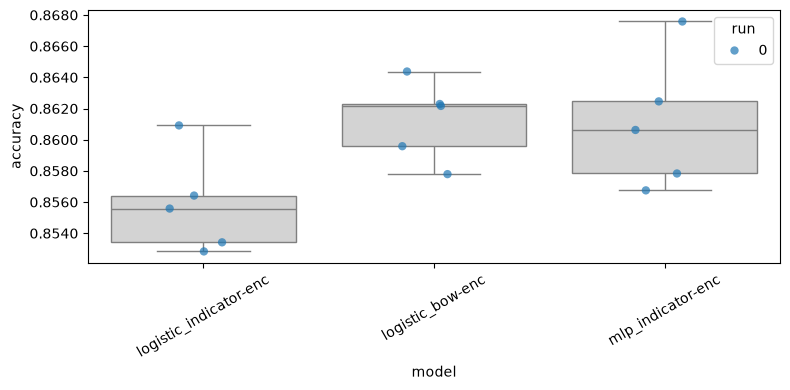

In [72]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

And you can try it out with your bag-of-words encoder.

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 27.713 seconds
Dataloader done! Time taken: 1.692 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7365 | train acc: 0.7476 | val loss: 0.4673 | val acc: 0.8445
Epoch 02 | train loss: 0.4469 | train acc: 0.8464 | val loss: 0.4170 | val acc: 0.8574
Epoch 03 | train loss: 0.4108 | train acc: 0.8566 | val loss: 0.4031 | val acc: 0.8603
Epoch 04 | train loss: 0.3951 | train acc: 0.8618 | val loss: 0.3943 | val acc: 0.8614
Epoch 05 | train loss: 0.3829 | train acc: 0.8653 | val loss: 0.3891 | val acc: 0.8636
Epoch 06 | train loss: 0.3745 | train acc: 0.8683 | val loss: 0.3846 | val acc: 0.8638
Epoch 07 | train loss: 0.3658 | train acc: 0.8712 | val loss: 0.3798 | val acc: 0.8660
Epoch 08 | train loss: 0.3571 | train acc: 0.8747 | val loss: 0.3764 | val acc: 0.8665
Epoch 09 | train loss: 0.3485 | train acc: 0.8764 | val loss: 0.3713 | val acc: 0.8675
Epoch 10 | train loss: 0.3400 | train acc: 0.8796 | val loss: 0.3674 | val acc: 0.8692
Training done! Time taken: 61.949 seconds
Transforming documents...
Document transformation done! Time taken: 27.776 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

...

Epoch 01 | train loss: 0.7229 | train acc: 0.7561 | val loss: 0.4639 | val acc: 0.8458
Epoch 02 | train loss: 0.4452 | train acc: 0.8469 | val loss: 0.4141 | val acc: 0.8591
Epoch 03 | train loss: 0.4117 | train acc: 0.8567 | val loss: 0.3995 | val acc: 0.8618
Epoch 04 | train loss: 0.3946 | train acc: 0.8618 | val loss: 0.3929 | val acc: 0.8648
Epoch 05 | train loss: 0.3830 | train acc: 0.8655 | val loss: 0.3876 | val acc: 0.8668
Epoch 06 | train loss: 0.3740 | train acc: 0.8686 | val loss: 0.3832 | val acc: 0.8675
Epoch 07 | train loss: 0.3657 | train acc: 0.8708 | val loss: 0.3800 | val acc: 0.8682
Epoch 08 | train loss: 0.3588 | train acc: 0.8728 | val loss: 0.3752 | val acc: 0.8695
Epoch 09 | train loss: 0.3489 | train acc: 0.8774 | val loss: 0.3722 | val acc: 0.8708
Epoch 10 | train loss: 0.3406 | train acc: 0.8796 | val loss: 0.3687 | val acc: 0.8714
Training done! Time taken: 61.098 seconds
Transforming documents...
Document transformation done! Time taken: 29.399 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7292 | train acc: 0.7526 | val loss: 0.4707 | val acc: 0.8417
Epoch 02 | train loss: 0.4437 | train acc: 0.8466 | val loss: 0.4219 | val acc: 0.8542
Epoch 03 | train loss: 0.4088 | train acc: 0.8571 | val loss: 0.4076 | val acc: 0.8577
Epoch 04 | train loss: 0.3920 | train acc: 0.8631 | val loss: 0.3993 | val acc: 0.8602
Epoch 05 | train loss: 0.3811 | train acc: 0.8666 | val loss: 0.3954 | val acc: 0.8607
Epoch 06 | train loss: 0.3708 | train acc: 0.8697 | val loss: 0.3903 | val acc: 0.8621
Epoch 07 | train loss: 0.3629 | train acc: 0.8728 | val loss: 0.3872 | val acc: 0.8623
Epoch 08 | train loss: 0.3542 | train acc: 0.8756 | val loss: 0.3812 | val acc: 0.8648
Epoch 09 | train loss: 0.3462 | train acc: 0.8780 | val loss: 0.3769 | val acc: 0.8662
Epoch 10 | train loss: 0.3365 | train acc: 0.8817 | val loss: 0.3740 | val acc: 0.8656
Training done! Time taken: 59.451 seconds
Transforming documents...
Document transformation done! Time taken: 27.922 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7262 | train acc: 0.7542 | val loss: 0.4725 | val acc: 0.8409
Epoch 02 | train loss: 0.4438 | train acc: 0.8474 | val loss: 0.4238 | val acc: 0.8522
Epoch 03 | train loss: 0.4089 | train acc: 0.8591 | val loss: 0.4087 | val acc: 0.8569
Epoch 04 | train loss: 0.3935 | train acc: 0.8633 | val loss: 0.4030 | val acc: 0.8578
Epoch 05 | train loss: 0.3825 | train acc: 0.8663 | val loss: 0.3966 | val acc: 0.8595
Epoch 06 | train loss: 0.3728 | train acc: 0.8692 | val loss: 0.3915 | val acc: 0.8622
Epoch 07 | train loss: 0.3642 | train acc: 0.8723 | val loss: 0.3884 | val acc: 0.8632
Epoch 08 | train loss: 0.3561 | train acc: 0.8746 | val loss: 0.3852 | val acc: 0.8629
Epoch 09 | train loss: 0.3480 | train acc: 0.8763 | val loss: 0.3791 | val acc: 0.8656
Epoch 10 | train loss: 0.3397 | train acc: 0.8801 | val loss: 0.3770 | val acc: 0.8643
Training done! Time taken: 61.662 seconds


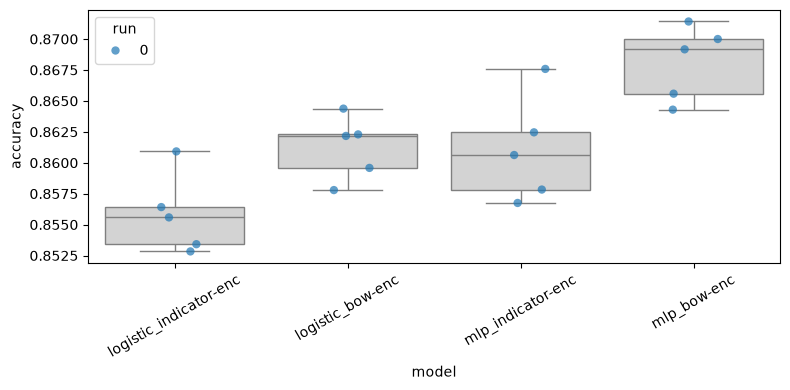

In [73]:
try:
    from part1 import solutions
except ImportError:
    print("You need your own implementation of the bag-of-words encoder")
else:
    my_classifiers['mlp_bow-enc'] = []
    for run, seed in enumerate(my_seeds):
        run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
        my_classifiers['mlp_bow-enc'].append(
            solutions.cross_validation_experiment_with_bow_encoder(
                data_splits=my_cross_validation_sets[run],
                tokenizer=tokenizer,
                model_option='mlp',
                save_to=run_folder,
                smlp_args={
                    'hidden_dim': 128, 
                    'dropout': 0.1, 
                    'batch_size': 64, 
                    'learning_rate': 1e-4, 
                    'weight_decay': 1e-4, 
                    'num_epochs': 10,
                }
            )
        )
    
    analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

Differences are small but they seem noticeable, at least at this level of analysis.

## Picking Amongst Design Choices

> This is section concerns statistical analysis of classifiers. The main learning outcomes here are not NLP-specific and hence you might skip this section in a first pass through the _Experiment_ section. Though this will remain relevant to your mini project.

We have now obtained models that differ in their design (e.g. different document representation, different model architecture, etc.), and hence, differ too in their performance across validation folds.  It is not straightforward to use their performance across validation folds to decide on which model, if any, we should prefer. We may have our own preferences motivated by things other than performance (for example, tractability, computational resources, etc.), here we leave those out and focus on a way to factor accuracy in.

We could take the average performance across folds to be representative of the system, but, if we are honest, that number is itself a random variable: change the seed for data splitting and other random things (perhaps internal to the optimisers we used) and the average accuracy across folds is likely to change; change the number of folds and things will change, etc.

**Suggested exercise:** why don't you test the claim above? 

If you took any classic _Stats 101_ course before, you are probably thinking _what significance test am I going to use?_

Well, that's not the answer we will be investigating in this tutorial. There are a number of reasons for that; one is that if all you took was some _Stats 101_, we think you could use a breather from frequentism; another, better one, is that null hypothesis signifance testing (NHST for short) is no longer an answer you should accept uncritically, see for example [Wasserstein et al 2019](https://www.tandfonline.com/doi/full/10.1080/00031305.2019.1583913). (Don't be mislead by the fact that the paper is from 2019; the problems with NHST have been documented for _decades_.)

There is _far_ too much we can objectively and decisively criticise about the logic and practice of NHST, and we don't have the space here (but, if you want an excellent book-length argument, read [Aubrey Clayton's excellent 2021 book](https://cup.columbia.edu/book/bernoullis-fallacy/9780231199957/)). So, we will echo a modern position in statistics, by authors of modern textbooks such as [BDA3](https://sites.stat.columbia.edu/gelman/book/), [Statistical Rethinking](https://xcelab.net/rm/), and [Bayesian Workflow](https://avehtari.github.io/Bayesian-Workflow/), and leave it at that. The position, in our own words, is: 

> We should regard statistics as a tool to help _represent and communicate uncertainty_. This is so because that is what a decision maker needs for informed action. Frequentist NHST _does not_ represent and communicate uncertainty, rather it washes uncertainty off. For at least that reason, NHST is not an appropriate tool for us. 

We will use something known as Bayesian _estimation_. In contrasting this to Frequentist NHST, you should focus on the word _estimation_, in contrast to _testing_, much more so than on the word _Bayesian_, in contrast to Frequentist; being Bayesian, rather than Frequentist, simply enables us to represent uncertainty about a what we do not know (e.g., which inferences are probable) given what we do know (e.g., that these accuracies were measured) and _that_ is what the word _estimation_ conveys (if you translate it from Bayesian lingo to plainer English). A good paper discussing this contrast is [Bayesian estimation supersedes the t-test](https://bpb-us-w2.wpmucdn.com/sites.umassd.edu/dist/f/1316/files/2023/01/Bayesian-estimation-supersedes-the-t-test.pdf). Bayesian estimation requires a _generative model_ of the data being analysed, for this tutorial we use a model proposed within the ML community, see next.

### Data analysis model

**The data** to be analysed is the collection of accuracies we measured. **The goal** of the analysis is to characterise something like an 'expected difference in performance' betweem two systems (it is possible to generalise this to more than two, indeed that is one of the many benefits of Bayesian estimation, but we won't be doing it in this tutorial).  

**The analysis model:**

The model used in this section is from [Benavoli et al 2017 (section 3)](https://jmlr.org/papers/volume18/16-305/16-305.pdf). In a nutshell, we model the accuracy differences in each fold as draws from a certain joint distribution over observed data (the measured differences) and hypothetical unknowns (e.g., expected difference, standard deviation, etc.). What we borrow from Benavoli et al then is a specific design for this joint distribution, including the specific unknowns and the distributions necessary to specify them. Here is a gist:

* We assume that observed accuracy differences in each fold are drawn from a normal distribution with unknown location (ie, mean difference between systems) and unknown scale (ie, standard deviation in accuracies).
* The mean difference is unknown and needs a distribution of its own, a prior. We pick a Student-t distribution because its heavy tails reserve non-negligible probability mass to observations far away from its mean, a good thing when we don't know much about how the unknown mean may distribute.
* Other unknowns also get reasonable priors. By _reasonable_ we mean that a range of relevant parameter values should be probable under the prior.

This is a specification of how we intended to _represent uncertainty_. The concrete representation is what we get once we condition on the observed data and _infer_ the posterior distribution over unknowns (this can be done exactly in some cases, for all other cases, sampling is a viable option in principle). BDA then is about updating our _reasonable but data-uninformed_ prior beliefs about parameters to _data-conditioned_ posterior beliefs. Once that is done, we _communicate_ our revised beliefs in a few ways, most notably, by plotting our posterior distributions.

In between _Inference_ and _Communication_ we have something called _model checking_, this is a part of the Bayesian workflow that is particularly interesting for it allows one to criticise _and_ improve the analysis model. Here we will not be doing any model checking, but for applications more complex than this and analysis models less tested than this, model checking is essential.

To support decision making, it's useful to summarise the posterior in some way. A common tool here is the _region of practical equivalence_ (or ROPE). This is the idea that in a given community of users, one is able to pick (and motivate) a magnitude of _difference_ that is judged as _worth the effort_. Of course, this will vary from application domain to application domain and it is not something a statistician can help you determine. To illustrate the point, this is _our strategy_ for this tutorial: If you look at the papers out there in NLP conferences, an accuracy gain that is believed to be in the ballpark of less than half a percent point is typically dismissed as _uninteresting_; so, we will take expected differences of 0.005 accuracy points or less to mean _practical equivalence_.



<details>
    <summary> Expand if you prefer a more mathy explanation.
    </summary></br>

Bayesian analysis works by describing a generative model of the data available to us, in this case, the evaluation data obtained via cross validation. In this case, we are interested in modelling the difference in classification performance between two classifiers; suppose we measure accuracy (but it could be another metric) for our system A on $k$ folds, obtaining measurements $a_1, \ldots, a_k$, and similarly for system B, obtaining measurements $b_1, \ldots, b_k$; then, for Bayesian analysis, the _observed_ data is the data vector $\mathbf m = (b_1-a_1, \ldots, b_k-a_k)^\top$. In general, we may have performed $r$ runs of $k$-fold cross validation, so let's say that the data vector contains $N = k \times r$ observed measurements.

We assume that these measurements can be drawn from a multivariate normal (MVN) distribution. The unknown mean difference is the same for all measurements, let's call it $\mu$. So the MVN's location (or mean vector) is the vector of $N$ copies of $\mu$, we can denote it compactly as $\mathbf 1_N \mu$. The MVN's covariance matrix $\mathbf \Sigma$, captures the correlations between our measurements, after all, there's great overlap in the training data underlying these measurements, due to cross validation. We take these correlations to be governed by an unknown scale (or standard deviation) $\sigma$ and a correlation coefficient $\rho$. So we design $\mathbf\Sigma$ with diagonal $\operatorname{diag}(\sigma^2)$ and $\rho\sigma^2$ for the rest. Now, we need to make some choices regarding the unknowns. We follow Benavoli here. That is, 

* we place a student-t prior on $\mu$; this is good because the heavy tails of the $t$ reserves non-negligible probability mass to observations far away from its mean (something a Normal distribution for mean difference cannot do), making the analysis more robust;
* we place a uniform prior on $\sigma$; again, this is good, for it allows a range of hypotheses about the scale of the data to be taken into account (other popular choices include an Exponential or Gamma prior);
* there's no prior for $\rho$, instead Benavoli uses a heuristic proposed and tested previously in the literature.

So the generative model looks like this
* $\mathbf m \sim \operatorname{MVN}(\mathbf 1 \mu, \mathbf \Sigma)$ 
* $\mu \sim t(\mu_0, \sigma_0, \nu)$
* $\sigma \sim \operatorname{unif}(0, \bar{\sigma})$

The choices for $\mu_0$, $\sigma_0$, $\nu$ and $\bar{\sigma}$ are taken from Benavoli. They are motivated and discussed there, and we will not repeat their reasons here, for brevity.

In Benavoli et al this is called _correlated t-test_ and its generalisation for multiple datasets is called _hierarchical t-test_. The simple form above, for a single dataset, is such that the posterior on $\mu$ is itself a student-t; with multiple datasets, a closed-form solution isn't possible, so one needs to use sampling-based inference (`baycomp`'s implementation relies on yet another package, `pystan`, and you might struggle getting it installed; if you wanted to try this out, we would suggest writing up a modern implementation in `numpyro` or `pymc`).


---

</details>
</details></br>


**Credit**

Bayesian estimation with this specific model formulation came to be known in machine learning ([Benavoli et al 2017](https://jmlr.org/papers/volume18/16-305/16-305.pdf)) as _Bayesian correlated t-test_. In the opinion of the authors of this tutorial, that is an unfortunate label, for it suggests that there is a _test_ in place; well, there really isn't one (as Benavoli et al explain in section 3 of their article), and our guess is that Benavoli et al named it this way to get those already using NHST to switch camps. A better way to encourage the switch is via reasoning and argumentation, so we encourage you to read the arguments in [section 2.1 of their work](https://jmlr.org/papers/volume18/16-305/16-305.pdf) or in the many links in this section of our tutorial. 

Bayesian modelling is transparent and demands knowledge that is generally more accessible than what is needed to understand and judge Frequentist statistics. This probably sounds strange at first, but it is largely true. There are two difficulties facing anyone interested in Bayesian statistics. First, most courses are taught entirely from a frequentist perspective, this means that Bayesian concepts are either not taught or taught with a great deal of mental contortionism. If you are curious, here are some talks that labour this point: [Bayesian Statistics without Frequentist Language](https://www.youtube.com/watch?v=yakg94HyWdE&t=2549s) and [All About that Bayes](https://www.youtube.com/watch?v=eDMGDhyDxuY&t=2029s). Second, Bayesian statistics is, by design, less _automated_ and this then demands some level of statistical thinking and training that many of us did not get. This is not the place to cover such gaps in most people's education, so we will have to delegate the work to a [library call](https://baycomp.readthedocs.io/en/latest/functions.html#baycomp.two_on_single). Please don't take this to mean that frequentist tools are a bad way to automate decision making and that Bayesian tools should be preferred, rather, we think you should not be automating your decisions, and, if you believe you need some statistical inference to support your decision making, then we advise you to take the steps you can to overcome frequentism.

Here is how you can use the lib to make some informed decisions:

In [74]:
# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in my_classifiers[sys_name]])

# this will have shape [num_runs, num_folds]
get_all_measurements_for(my_classifiers, 'logistic_indicator-enc')

array([[0.85558333, 0.85641667, 0.86091667, 0.85341667, 0.85283333]])

A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=0.0001 P(Tie)=0.3949 P(B wins)=0.6050


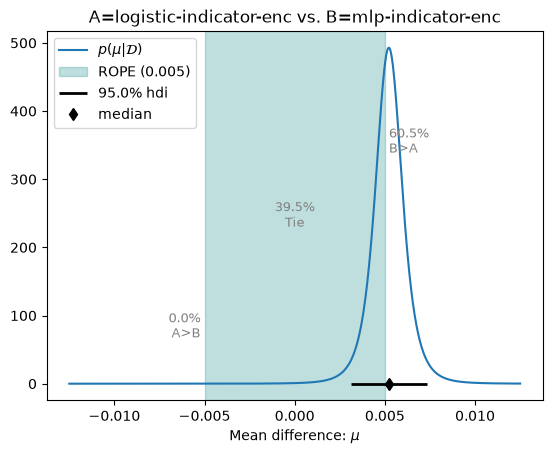

In [75]:
posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(my_classifiers, 'mlp_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    names=["logistic-indicator-enc", "mlp-indicator-enc"]
)
p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f}")
_ = posterior.plot(0.005)  # if you need to zoom in or out reduce/increase the argument rope_factor (it doesn't affect the ROPE, only the visualisation of it)

The plot shows the mean difference in the horizontal axis, and, in blue, the posterior distribution of mean differences. The ROPE is shown with a shaded area. 
With a fixed ROPE, we can calculate the area under the posterior that falls within, before or after the ROPE, and this way we have an expectation about where the unknown mean difference falls, given the observed accuracies of two systems across folds. 

**How do we use this to make a decision?**

* You get a sense of how confident you can be in your belief that some design choices are better than others; you can use the plot to calibrate your own expectations and you also get an idea of what kinds of differences you can expect.
* Statistics cannot give you a decision; but it informs you by communicating residual uncertainty once you incorporate your assumptions and observations; you can then take your practical considerations into account and perhaps decide _oh okay, I am willing to update my own belief that design choice B is a better call than design choice A, and if my assumptions (statistical and practical) are representative of my community of peers, then they will most likely be willing to update their own beliefs in the same way_.


If you compare other model pairs, you will see that some cases are clearly inside the ROPE (e.g., logistic-bow vs. mlp-indicator), others aren't. That, of course, for a ROPE of size 0.005. 

A                       B                    A wins     Tie    B wins
----------------------  -----------------  --------  ------  --------
logistic_indicator-enc  mlp_indicator-enc    0.0001  0.3949    0.6050
logistic_indicator-enc  mlp_bow-enc          0.0000  0.0006    0.9993
logistic_bow-enc        mlp_indicator-enc    0.0170  0.9695    0.0135
logistic_bow-enc        mlp_bow-enc          0.0001  0.0461    0.9538


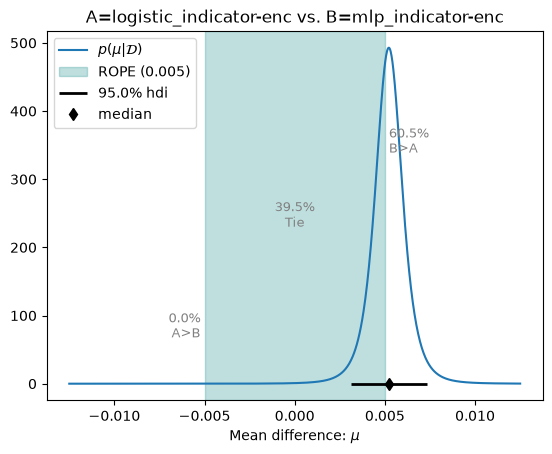

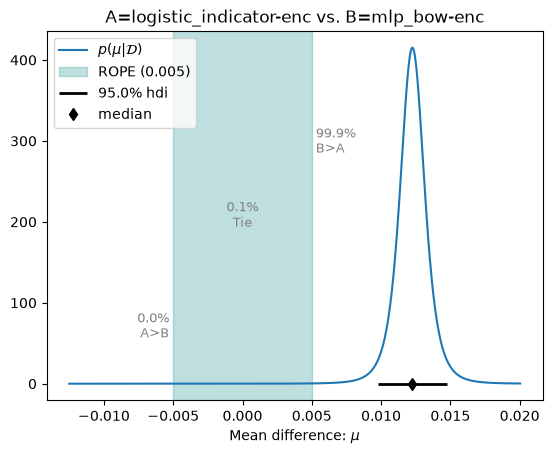

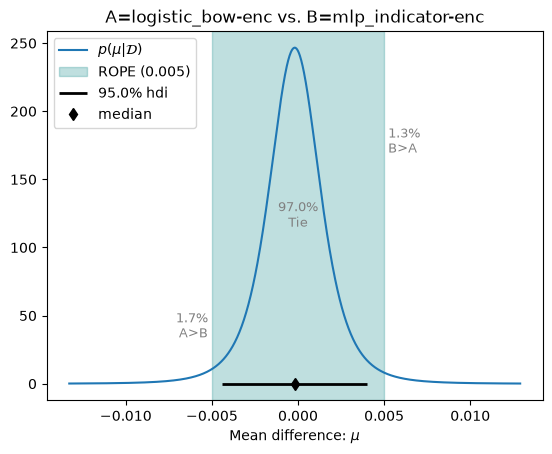

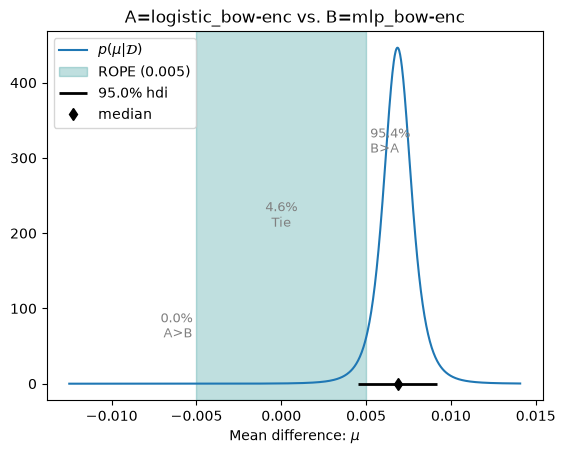

In [76]:
try:
    from part1 import solutions
except ImportError:
    print("You need your own implementation of the bag-of-words encoder")
else:    
    table = []
    rope_size = 0.005
    for sys_a in ['logistic_indicator-enc', 'logistic_bow-enc']:
        for sys_b in ['mlp_indicator-enc', 'mlp_bow-enc']:
            posterior = analysis.BenavoliCorrelatedT(
                get_all_measurements_for(my_classifiers, sys_a).flatten(), 
                get_all_measurements_for(my_classifiers, sys_b).flatten(), 
                names=[sys_a, sys_b]
            )
            p_a, p_tie, p_b = posterior.probs(rope_size)
            table.append([sys_a, sys_b, p_a, p_tie, p_b])            
            _ = posterior.plot(rope_size);            
    print(tabulate(table, headers=["A", "B", "A wins", "Tie", "B wins"], floatfmt=".4f"))

## Questions

1. Instead of running a tokenisation algorithm, such as BPE, a very simplistic approach would be to simply use Unicode (i.e., character level segmentation) for our classifier. Do you think that'd be a good idea? Why or why not?
2. Is a larger vocabulary necessarily better?
3. Do you think a more linguistically-informed tokenizer (such as those from NLTK) would do better or worse, and why?
4. We have trained our BPE tokeniser and our classifier on a news articles corpora. What do you think happens when the tokenizer and the classifier are trained on different data, say the tokenizer is trained on unlabelled [European parliament proceedings](https://www.statmt.org/europarl/) and the classifier on AG-news (or whatever labelled resource you have)? 
5. Discuss two ideas to improve the text representations we use. In particular, focus on ideas that you believe you can deploy in code and explain why your belief is reasonable. 
6. Discuss one idea to improve the model architecture. Again, focus on an idea that you believe you can deploy in code and explain why your belief is reasonable. 
7. We use accuracy to validate our models. How could you use your labelled data to defend or challenge this choice? If you had to challenge it, what would you suggest in its place and why?